# Forecasting Emerging Drug-Safety Signals in FAERS

Can we flag drug–event pairs before they become strong disproportionality signals? Case study: SGLT2 inhibitors and GLP-1 receptor agonists, FDA Adverse Event Reporting System (FAERS), 2014–2019

## Purpose
Earlier notebooks cleaned the FAERS reports, built a dataset for seven diabetes medicines and identified 835 potential safety signals (613 strong) with disproportionality analysis (DPA). That analysis is retrospective: it tells us which pairs are signals at the end of 2019.

This notebook asks a forward-looking question: using only the reports available at a given date, can we rank the pairs that are not yet signals so that the ones that become strong signals within the next 12 months are near the top of the list? A safety reviewer could then look at that short watch list first.

**Approach in brief**
1. Rebuild the monthly history of every medicine–event pair (report counts, expected counts, EBGM and EB05) and check that it reproduces the final signal results (Sections 1–2).
2. Define the target. A pair "emerges" when it first stays a strong signal for 3 consecutive months. Early-2014 onsets are treated as start-up artefacts and excluded (Section 3).
3. Walk-forward test. At each quarter-end (the cutoff) rank the not-yet-signalled pairs using only data up to that date, then check which ones became strong signals in the following 12 months (Section 4).
4. Compare methods at the same alert budget (top 5% of the ranking): today's EB05 (baseline), machine-learning models on report-history features, and rankings based on a forecast of future report counts (Sections 5–9).

## Key terms

| Term | Meaning |
|---|---|
| **Pair** | One medicine (active ingredient) combined with one adverse-event term (MedDRA preferred term, PT). |
| **a** | Cumulative number of reports, from Jan 2014, in which the medicine is the primary suspect and the event is reported. |
| **E** | Expected value of *a* if the medicine were unrelated to the event, given how often the event is reported across FAERS (Section 2.1). |
| **EBGM / EB05** | Empirical-Bayes (Gamma–Poisson shrinker) estimate of how much more often the event is reported than expected, and its lower 5% bound. EB05 ≥ 2 is the strength criterion. |
| **Signal** | A pair meeting the Evans, ROR and IC criteria defined in the signal-identification notebook (at least 3 reports). |
| **Strong signal** | A signal that also has EB05 ≥ 2. |
| **Noise** | Pairs excluded in the signal-identification notebook as not representing genuine safety events. |
| **Onset** | First month of a run of *K* = 3 consecutive months in which the pair is a strong signal. |
| **Burn-in** | Onsets up to Jun 2015 are ignored as targets, because counts start from zero in Jan 2014 and established pairs "arrive" in 2014–2015 (Section 3.4). |
| **Cutoff *t*, horizon *H*** | The date at which a ranking is made (quarter-ends) and the look-ahead window, *H* = 12 months. |
| **At-risk pair** | A pair with *a* ≥ 3 at *t* that has not yet been a strong signal. Only these are ranked. |
| **Watch list / alert budget** | The top 5% of at-risk pairs by score at each cutoff. Every method gets the same budget. |
| **Average precision (AP)** | Area under the precision–recall curve; chance level equals the share of positives (about 2–6% per cutoff). |
| **Recall in top 5%** | Share of the pairs that become strong within 12 months that are on the watch list. |
| **Lift** | AP divided by the share of positives. |

## Comparison arms

| Arm | Score used to rank at-risk pairs |
|---|---|
| **A** | EB05 at the cutoff (the traditional DPA score). Report count *a* alone is shown as a negative control. |
| **B1 / B2** | Predicted probability from logistic regression / gradient boosting using features known at the cutoff: EB05, EBGM, report count, 3- and 6-month growth in counts and EB05, months since the pair reached 3 reports, drug class. |
| **C1 / C2** | EB05 recomputed from a forecast of *a* and *E* 12 months ahead: C1 = flat (average recent monthly increase), C2 = linear trend. |
| **D** | Logistic regression on the B1 level-and-age features (S1) plus the C1 forecast features. |
| **S0 / S1 / S2** | Feature sets used in the ablation: EB05 only / plus count, age and class / plus growth. |

## Inputs, outputs and requirements

* **Database:** `data/faers_db.duckdb`, containing the tables built in earlier notebooks (`pair_month`, `pair_counts`, `signal_ts`, `signal_labels`, `ref_known_signal`, `m_grp`, `v_pair_stats`). The notebook **writes** two tables: `fc_pair_month_e` and `fc_pair_month_eb`.
* **Files:** `outputs/signal_identification_v1/` from the signal-identification notebook (`sig_final.csv`, `res_raw.csv`, `ebgm_prior.csv`).
* **Written by this notebook:** onset-label CSVs (`onset_labels_*.csv`) and figures (`figures/*.png`) in the same folder.
* **Python 3.10+** with `duckdb`, `pandas`, `numpy`, `scipy`, `scikit-learn`, `matplotlib`.

## 0. Setup

### 0.1 Imports and configuration

In [2]:
import warnings
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import brentq
from scipy.special import digamma, gammaln
from scipy.stats import gamma

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [3]:
# Folder with the outputs of the signal-identification notebook (inputs here).
# The onset-label CSVs and the figures written by this notebook go to the same folder.
SIG_DIR = Path("outputs/signal_identification_v1")
FIG = SIG_DIR / "figures"
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

def save(name):
    """Save the current matplotlib figure to FIG and show it."""
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

### 0.2 Connect to the database

The connection is opened with `read_only=False` because this notebook creates two tables (`fc_pair_month_e`, `fc_pair_month_eb`). Use `read_only=True` if you only want to inspect the data.

In [4]:
# Path to the DuckDB database (project root/data/faers_db.duckdb)

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DB_PATH = PROJECT_ROOT / "data" / "faers_db.duckdb"

con = duckdb.connect(str(DB_PATH), read_only=False)  # read_only=False: this notebook creates two tables

Tables available in the database:

In [5]:
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_colwidth", 50)
print(con.sql("SHOW TABLES").df())

                     name
0               case_base
1               case_drug
2           case_exposure
3              case_month
4            case_outcome
5                 case_pt
6             case_source
7              clean_demo
8                 demo_us
9             drug_detail
10               exposure
11             faers_flat
12        fc_pair_month_e
13       fc_pair_month_eb
14                    m_N
15                   m_ev
16                  m_grp
17                 m_pair
18                 months
19            pair_counts
20              pair_grid
21             pair_month
22                ps_case
23          ps_case_event
24                ps_drug
25               raw_demo
26               raw_indi
27               raw_reac
28               raw_ther
29               ref_drug
30       ref_known_signal
31          signal_labels
32              signal_ts
33       study_case_event
34            study_cases
35        study_drug_rows
36   v_ingredient_summary
37   v_known

In [ ]:
pair_counts = con.sql("SELECT * FROM pair_counts").df()
pair_month= con.sql ("SELECT * FROM pair_month").df()
pair_grid= con.sql ("SELECT * FROM pair_grid").df()
v_signals= con.sql ("SELECT * FROM v_signals").df()
ps_case_event= con.sql ("SELECT * FROM ps_case_event").df()
m_pair= con.sql ("SELECT * FROM m_pair").df()
signal_labels= con.sql ("SELECT * FROM signal_labels").df()
signal_ts= con.sql ("SELECT * FROM signal_ts").df()
m_grp= con.sql ("SELECT * FROM m_grp").df()

## 1. Inputs and consistency checks

The forecasting target is built from the monthly history of each pair, so we first verify that this history reproduces the final results of the signal-identification notebook.

### 1.1 Load the signal-identification outputs

* `sig`: one row per pair (9,251) with the final signal tiers.
* `res_raw`: EBGM, EB05 and expected count *E* per pair at the end of 2019.

In [6]:
sig = pd.read_csv(SIG_DIR / "sig_final.csv")
res_raw = pd.read_csv(SIG_DIR / "res_raw.csv")

### 1.2 Check that the files loaded correctly

The counts should match the signal-identification notebook: 9,251 pairs, 8,740 analysed after removing noise, 835 signals and 613 strong signals.

In [7]:
# Check if correctly loaded
print(sig.shape)   # expect 9,251 rows
print(sig.dtypes[["is_noise","signal","strong"]])    
print(sig.tier.value_counts())                      
nn = sig[~sig.is_noise]
print(len(nn), nn.signal.sum(), nn.strong.sum())    # analysed, signals, strong
print(nn.groupby("ingredient")[["signal","strong"]].sum())

(9251, 32)
is_noise    bool
signal      bool
strong      bool
dtype: object
tier
3 Not flagged           7905
1 Strong                 613
0 Noise (excluded)       511
2 Signal, not strong     222
Name: count, dtype: int64
8740 835 613
               signal  strong
ingredient                   
canagliflozin     243     191
dapagliflozin     161     114
dulaglutide        84      59
empagliflozin     154     113
ertugliflozin      15      11
liraglutide       112      80
semaglutide        66      45


### 1.3 Inspect the database tables used

`signal_labels` (a first, simple onset label), `ref_known_signal` (known FDA safety communications used as reference cases) and `pair_counts` (final 2×2 counts per pair).

In [8]:
print(con.sql("SELECT * FROM signal_labels LIMIT 5").df().to_string())
print(con.sql("SELECT * FROM ref_known_signal").df().to_string())
print(con.sql("SELECT * FROM pair_counts LIMIT 5").df().to_string())

      ingredient                   pt      onset    status
0  canagliflozin    AMYLASE INCREASED        NaT     never
1  canagliflozin           ANGIOPATHY        NaT     never
2  canagliflozin           ARTHRALGIA        NaT     never
3  canagliflozin  ARTHRITIS BACTERIAL 2018-02-01  emerging
4  canagliflozin  BACTERIAL INFECTION        NaT     never
      ingredient      pt_regex   reg_date                                   source
0  dapagliflozin  KETOACIDOSIS 2015-05-15         FDA DSC: SGLT2i and ketoacidosis
1  empagliflozin  KETOACIDOSIS 2015-05-15         FDA DSC: SGLT2i and ketoacidosis
2  canagliflozin  KETOACIDOSIS 2015-05-15         FDA DSC: SGLT2i and ketoacidosis
3  canagliflozin    AMPUTATION 2016-05-18  FDA DSC: interim CANVAS amputation risk
4  dapagliflozin      FOURNIER 2018-08-29  FDA DSC: SGLT2i and Fournier's gangrene
5  empagliflozin      FOURNIER 2018-08-29  FDA DSC: SGLT2i and Fournier's gangrene
6  canagliflozin      FOURNIER 2018-08-29  FDA DSC: SGLT2i and Fo

### 1.4 Check that the monthly tables reproduce the final results

* **A. Coverage:** which pairs are in the monthly tables.
* **B.** Does the last month of `pair_month` equal `pair_counts`?
* **C.** Does the last month of `signal_ts` equal the final signal count?
* **D.** How do the earlier `signal_labels` relate to the final state?

In [9]:
# A. coverage
print(con.sql("""SELECT COUNT(*) pairs FROM (SELECT DISTINCT ingredient, pt FROM pair_month)""").df())
print(con.sql("""SELECT COUNT(*) pairs, MIN(a) min_a, MIN(m), MAX(m) FROM
                 (SELECT ingredient, pt, a, m FROM signal_ts)""").df())

# B. does the last month of pair_month reproduce pair_counts?
print(con.sql("""
WITH l AS (SELECT * FROM pair_month WHERE m = (SELECT MAX(m) FROM pair_month))
SELECT COUNT(*) n_joined,
       SUM((l.a <> f.a)::INT)                     a_diff,
       SUM((l.n_exp <> f.n_exp)::INT)             exp_diff,
       SUM((l.n_excl <> f.n_excl)::INT)           excl_diff,
       SUM((l.n_event_all <> f.n_event_all)::INT) ev_all_diff,
       SUM((l.n_event_excl <> f.n_event_excl)::INT) ev_excl_diff,
       SUM((l.N <> f.N)::INT)                     N_diff
FROM l JOIN pair_counts f USING (ingredient, pt)""").df())

# C. does the last month of signal_ts reproduce the final signal count?
print(con.sql("""
SELECT (SELECT COUNT(*) FROM signal_ts WHERE signal AND m = (SELECT MAX(m) FROM signal_ts)) AS ts_last_month,
       (SELECT COUNT(*) FROM v_pair_stats WHERE signal) AS final_signal""").df())

# D. how labels relate to the final state
print(con.sql("""
SELECT l.status, COUNT(*) n, SUM(COALESCE(s.signal, FALSE)::INT) still_signal_at_end
FROM signal_labels l LEFT JOIN v_pair_stats s USING (ingredient, pt)
GROUP BY ALL""").df())

   pairs
0   3870
    pairs  min_a     min(m)     max(m)
0  191758    1.0 2014-01-01 2019-12-01
   n_joined  a_diff  exp_diff  excl_diff  ev_all_diff  ev_excl_diff  N_diff
0      3870     0.0       0.0        0.0          0.0           0.0     0.0
   ts_last_month  final_signal
0            955           955
         status     n  still_signal_at_end
0         never  2732                  0.0
1  pre-existing   174                134.0
2      emerging   964                821.0


**What the checks show.** All four checks pass.

* **A and B: `pair_month` is a valid base for the monthly panel.**
    * The 3,870 pairs are by design, not a gap. In the signal-identification notebook 5,381 of the 9,251 pairs have *a* < 3, and 9,251 − 5,381 = 3,870. The monthly tables therefore contain exactly the pairs with final *a* ≥ 3. Pairs below 3 reports can never be flagged, so nothing is lost for the forecasting target.
    * The last month of `pair_month` reproduces `pair_counts` exactly: zero differences in *a*, `n_exp`, `n_excl`, `n_event_all`, `n_event_excl` and *N* for all 3,870 pairs.
* **C: `signal_ts` reproduces the final signals.** The last month has 955 signals, equal to the 955 in `v_pair_stats`. This is the *before-noise-removal* count under the Evans ∧ ROR ∧ IC rule, and matches the per-drug sum (251 + 172 + 132 + 162 + 21 + 136 + 81). Section 2.3 shows that removing noise gives the 835 signals and 613 strong signals of the final analysis.
* **D: relation of the earlier labels to the final state.** 964 + 174 = 1,138 pairs were *ever* signalled; 821 + 134 = 955 are signalled at the end. The difference of 183 pairs (16%) crossed the threshold at some month and later fell out again.
    * `signal_labels` covers the same 3,870 pairs, but it uses the Evans ∧ ROR ∧ IC rule without EB05 and without the noise list, so it cannot serve as the strong-signal target.
    * The 183 pairs that "flicker" show that defining onset as the *first month with signal = true* would be unstable: a pair that crosses once and drops out would count as emerged. **Design decision:** onset is the first month of a *sustained* run of strong months (Section 3).
    * `pre-existing` pairs have an onset in 2014. They are start-up (burn-in) cases and are kept as controls rather than positives.

## 2. Monthly signal statistics

The final analysis computed *E*, EBGM and EB05 once, at the end of 2019. For forecasting we need the same quantities **for every month**, computed with exactly the same formulas. We reproduce them step by step and validate each step against the final results.

### 2.1 Expected counts *E*

#### Which formula reproduces the final *E*?

We compare five candidate formulas for *E* with the `E` stored in `res_raw`. The first candidate (E1) is the textbook formula; the others adjust for the reports excluded from the comparison group.

In [10]:
cand = con.sql("""
SELECT ingredient, pt,
  n_exp * n_event_all::DOUBLE / N                               AS E1,
  n_exp * (n_event_all - n_event_excl)::DOUBLE / N              AS E2,
  n_exp * n_event_all::DOUBLE / (N - n_excl)                    AS E3,
  n_exp * (n_event_all - n_event_excl)::DOUBLE / (N - n_excl)   AS E4,
  n_exp * (n_event_all - a)::DOUBLE / (N - n_exp)               AS E5
FROM pair_counts""").df()
m = cand.merge(res_raw[["ingredient","pt","E"]], on=["ingredient","pt"])
for k in ["E1","E2","E3","E4","E5"]:
    r = (m.E - m[k]).abs() / m.E
    print(k, "median", r.median(), "max", r.max(), "n>1e-6:", (r > 1e-6).sum())

E1 median 0.0004633228772463229 max 0.49873842204509283 n>1e-6: 9238
E2 median 0.0006856806436353904 max 0.001415088546770406 n>1e-6: 9251
E3 median 0.0003663003663005389 max 0.5000000000000159 n>1e-6: 5440
E4 median 0.0 max 1.1988407130584498e-13 n>1e-6: 0
E5 median 0.00221523311589094 max 1.0 n>1e-6: 9247


**Result:** only **E4** reproduces the final *E* (maximum relative difference about 1e-13, no pair above 1e-6). The textbook formula E1 is off by up to 50%.

$$E = n_{	ext{exp}} \times \frac{n_{	ext{event,all}} - n_{	ext{event,excl}}}{N - n_{	ext{excl}}}$$

`E4` uses `n_excl`, so we next confirm what the exposed (`exp`) and excluded (`excl`) groups contain.

#### Confirm the exposed and excluded groups

`m_grp` holds the monthly case counts per ingredient and group. Their totals should equal `n_exp` and `n_excl` in `pair_counts`.

In [11]:
print(con.sql("SELECT ingredient, g, SUM(n) cases FROM m_grp GROUP BY ALL ORDER BY 1,2").df())

       ingredient     g    cases
0   canagliflozin  excl   4520.0
1   canagliflozin   exp  18865.0
2   dapagliflozin  excl   2414.0
3   dapagliflozin   exp   4851.0
4     dulaglutide  excl   2490.0
5     dulaglutide   exp  23381.0
6   empagliflozin  excl   3685.0
7   empagliflozin   exp   6407.0
8   ertugliflozin  excl     87.0
9   ertugliflozin   exp    358.0
10    liraglutide  excl   7605.0
11    liraglutide   exp  11604.0
12    semaglutide  excl    348.0
13    semaglutide   exp   2187.0


**The counts match** `m_grp` and `pair_counts` exactly (for example canagliflozin: 18,865 exposed and 4,520 excluded; liraglutide: 11,604 and 7,605). The definitions are therefore:

* **exp**: reports in which the ingredient is the **primary suspect**.
* **excl**: reports in which the ingredient appears in another role (any role *and not* primary suspect). They are removed from the comparison so that they do not dilute it.
* **Comparison group**: the 2014–2019 FAERS universe (*N* ≈ 5.37 million reports) minus the ingredient's `excl` reports. Following E4, this group still contains the ingredient's own primary-suspect reports, as in the standard EBGM expected count.

This is a **FAERS-wide comparison with a drug-specific exclusion**, not a comparison against other antidiabetics. For the methods text: *"Primary-suspect reports for each ingredient were compared against all FAERS reports in 2014–2019, excluding reports in which that ingredient was present as a non-primary-suspect drug."* An antidiabetic-only comparator was run as a separate sensitivity analysis in `03_Exploration.ipynb`.

#### Monthly *E*

Apply E4 to every pair and month, store the result in `fc_pair_month_e`, and check the last month against `res_raw`.

In [12]:
con.sql("""
CREATE OR REPLACE TABLE fc_pair_month_e AS
SELECT ingredient, pt, m, a, n_exp, n_excl, n_event_all, n_event_excl, N,
       n_exp * (n_event_all - n_event_excl)::DOUBLE / (N - n_excl) AS E
FROM pair_month
""")

chk = con.sql("""SELECT ingredient, pt, E FROM fc_pair_month_e
                 WHERE m = (SELECT MAX(m) FROM fc_pair_month_e)""").df()
mm = chk.merge(res_raw[["ingredient","pt","E"]], on=["ingredient","pt"], suffixes=("_ts","_res"))
print(len(mm), ((mm.E_ts - mm.E_res).abs() / mm.E_res).max())


3870 5.6952114976796085e-15


**Result:** 3,870 pairs with a maximum relative difference of about 6e-15, so the monthly *E* reproduces the final *E* at the last month.

### 2.2 EBGM and EB05

EBGM and EB05 come from a two-component Gamma mixture prior fitted in the signal-identification notebook. We load it **at full precision** from `ebgm_prior.csv`; rounding the parameters changes results by about 1e-4 and could flip pairs close to EB05 = 2.

In [13]:
# Load the fitted EBGM prior at full precision (rounding the parameters changes results by ~1e-4)

ebgm_prior = pd.read_csv(SIG_DIR / "ebgm_prior.csv").set_index("param").value
a1, b1, a2, b2, w = ebgm_prior.alpha1, ebgm_prior.beta1, ebgm_prior.alpha2, ebgm_prior.beta2, ebgm_prior.w
print(repr(a1), repr(b1), repr(a2), repr(b2), repr(w), ebgm_prior.nll)   # nll should be ~38967.333

np.float64(0.1183574110875787) np.float64(0.0284052511045657) np.float64(0.7925821291281991) np.float64(2.110050530096621) np.float64(0.1355067896056669) 38967.33295682843


#### The EBGM / EB05 function

`eb(n, E)` computes the posterior mixture for a pair with *n* reports and expected count *E*, and returns EBGM and EB05 (the 5th percentile of the posterior, found by root-finding). We test it on 300 randomly sampled pairs against the stored values.

In [14]:
# EBGM / EB05 for a pair with n reports and expected count E; test on 300 random pairs

def eb(n, E):
    def lm(al, be):
        return (gammaln(al+n) - gammaln(al) - gammaln(n+1)
                + al*np.log(be/(be+E)) + n*np.log(E/(be+E)))
    l1, l2 = np.log(w)+lm(a1,b1), np.log(1-w)+lm(a2,b2)
    mx = max(l1, l2)
    q1 = np.exp(l1-mx)/(np.exp(l1-mx)+np.exp(l2-mx)); q2 = 1-q1
    ebgm = np.exp(q1*(digamma(a1+n)-np.log(b1+E)) + q2*(digamma(a2+n)-np.log(b2+E)))
    cdf = lambda x: q1*gamma.cdf(x, a1+n, scale=1/(b1+E)) + q2*gamma.cdf(x, a2+n, scale=1/(b2+E))
    eb05 = brentq(lambda x: cdf(x)-0.05, 1e-12, 1e4)
    return ebgm, eb05

t = res_raw[res_raw.a >= 3].sample(300, random_state=1).copy()
t[["ebgm_t","eb05_t"]] = [eb(r.a, r.E) for r in t.itertuples()]
print((abs(t.ebgm_t-t.EBGM)/t.EBGM).max(), (abs(t.eb05_t-t.EB05)/t.EB05).max())

1.7573886600494276e-06 5.616079257999036e-06


Checking all 3,870 pairs: does the EB05 ≥ 2 classification change anywhere?

In [15]:
r = res_raw[res_raw.a >= 3].copy()
r[["ebgm_t","eb05_t"]] = [eb(x.a, x.E) for x in r.itertuples()]
flip = (r.eb05_t >= 2) != (r.EB05 >= 2)
print(len(r), flip.sum(), "classification flips")

3870 0 classification flips


**Result.** The EB calculation is reproduced: the 300 sampled pairs agree with the original results to a maximum relative difference of 1.8e-6 (EBGM) and 5.6e-6 (EB05), and across all 3,870 pairs there are **0 classification flips** at EB05 ≥ 2. The same `eb(a, E)` function can therefore be used for the monthly values. The remaining differences of about 1e-6 were not investigated further; they could matter only for pairs extremely close to the threshold.

**Scope of the validation.** This confirms the *computation*, not the statistical validity of the signals. The prior was fitted on data up to 2019, so monthly estimates in earlier years use information from the future. This potential leakage is listed under limitations (Section 11); a sensitivity analysis with the prior refitted at each year-end has **not** been run yet.

### 2.3 Monthly EB table

Compute EBGM and EB05 for every pair-month with *a* ≥ 3 (139,977 rows) and store them in `fc_pair_month_eb`. As validation, the last month is compared with `res_raw`.

In [16]:
# build and validate the monthly EB table
pm = con.sql("SELECT * FROM fc_pair_month_e WHERE a >= 3 AND E > 0").df()
print(len(pm), "rows to evaluate")

vals = np.array([eb(a, E) for a, E in zip(pm.a.values.astype(float), pm.E.values)])
pm["EBGM"], pm["EB05"] = vals[:, 0], vals[:, 1]

con.register("fc_eb_df", pm)
con.sql("CREATE OR REPLACE TABLE fc_pair_month_eb AS SELECT * FROM fc_eb_df")

# validation 1: last month vs res_raw
last = pm[pm.m == pm.m.max()].merge(res_raw[["ingredient","pt","EBGM","EB05"]],
                                    on=["ingredient","pt"], suffixes=("_m","_f"))
print(len(last),
      (abs(last.EBGM_m - last.EBGM_f)/last.EBGM_f).max(),
      (abs(last.EB05_m - last.EB05_f)/last.EB05_f).max())

139977 rows to evaluate
3870 1.864639644731256e-06 5.619094343622806e-06


Combine with the monthly signal flags (`signal_ts`) to define **strong = signal ∧ EB05 ≥ 2** per month, then remove the noise pairs. The last month should give 955 signals and 705 strong signals before noise removal, and 835 and 613 after, matching the final analysis.

In [17]:
fl = con.sql("""
SELECT s.ingredient, s.pt, CAST(s.m AS DATE) AS m, s.signal, e.EB05, e.EBGM, e.a
FROM signal_ts s JOIN fc_pair_month_eb e
  ON s.ingredient=e.ingredient AND s.pt=e.pt AND CAST(s.m AS DATE)=e.m
""").df()
fl["strong"] = fl.signal & (fl.EB05 >= 2)

lastm = fl[fl.m == fl.m.max()]
print(len(lastm), "signal", lastm.signal.sum(), "| strong (pre-noise)", lastm.strong.sum())

noise = pd.read_csv(SIG_DIR / "sig_final.csv",
                    usecols=["ingredient","pt","is_noise"])
lm = lastm.merge(noise, on=["ingredient","pt"], how="left")
print(lm.is_noise.isna().sum(), "pairs without a noise flag")
print("post-noise: signal", lm[~lm.is_noise].signal.sum(),
      "| strong", lm[~lm.is_noise].strong.sum())

3870 signal 955 | strong (pre-noise) 705
0 pairs without a noise flag
post-noise: signal 835 | strong 613


**Result:** the last month reproduces the final analysis exactly (955 → 835 signals and 705 → 613 strong signals after removing noise).

## 3. Defining the forecasting target (onset labels)

A pair is a *positive* at cutoff *t* if it **starts** a strong-signal run within the next 12 months. This section defines "start", justifies the two free choices (run length *K* and burn-in end) and saves the final labels.

### 3.1 Pair-month panel

Build `g`: one row per non-noise pair and month (3,542 pairs × 72 months = 255,024 rows) with the strong flag, EB05, EBGM and *a*. Months with *a* < 3 have no EB05 and count as *not strong*.

In [18]:
# `noise` (pairs flagged as noise) was loaded in Section 2.3
p = (fl.merge(noise, on=["ingredient","pt"], how="left")
       .query("~is_noise")
       .sort_values(["ingredient","pt","m"]).copy())

# full monthly grid per pair (months with a<3 count as not strong)
months = pd.date_range("2014-01-01", "2019-12-01", freq="MS")
idx = pd.MultiIndex.from_product(
    [p[["ingredient","pt"]].drop_duplicates().apply(tuple, axis=1), months],
    names=["pair","m"])

g = (p.assign(pair=list(zip(p.ingredient, p.pt)))
       .set_index(["pair","m"])[["strong","EB05","EBGM","a"]]
       .reindex(idx))
g["strong"] = g["strong"].astype("boolean").fillna(False).astype(bool)

print(g.shape, g.EBGM.notna().sum())       # (3542*72 = 255,024, 4); EBGM non-null where a>=3
print(g.EB05.notna().sum(), (g.EB05.notna() == g.EBGM.notna()).all())


(255024, 4) 127636
127636 True


### 3.2 The onset-label function

* **K**: onset = first month of a run of *K* consecutive strong months. A pair that crosses once and drops out is not an onset.
* **burn_in_end**: onsets on or before this month are left-censored (`control_burn_in`). Their true onset may lie before the data begin, because counts accumulate from an empty start in Jan 2014.
* **censored**: strong in Dec 2019 but the run is not yet *K* months long (right-censored). These pairs are neither positive nor negative and are excluded.
* **never**: no run of *K* strong months. **emerging**: onset after the burn-in date (the positives).

Setting `burn_in_end` before the data start (e.g. 2013-12-01) switches burn-in off; this is used for the raw onset histogram.

In [19]:
def make_labels(g, months, K, burn_in_end="2015-06-01"):
    def first_run(s):
        run = s.astype(int).rolling(K).sum().eq(K)   # True where K consecutive strong months end
        return run.idxmax()[1] if run.any() else pd.NaT

    onset = (g.groupby(level="pair").strong.apply(first_run)
               .rename("onset_run").reset_index())
    onset["onset_run"] = onset.onset_run - pd.DateOffset(months=K-1)   # first month of the run

    end = g.xs(months[-1], level="m").strong.rename("strong_at_end").reset_index()
    lab = onset.merge(end, on="pair")
    lab["burn_in"] = lab.onset_run <= pd.Timestamp(burn_in_end)
    lab["K"] = K
    lab["status"] = np.select(
        [lab.onset_run.isna() & lab.strong_at_end,   # strong only in the last K-1 months
         lab.onset_run.isna(),                      # never completed a run
         lab.burn_in],
        ["censored", "never", "control_burn_in"], default="emerging")
    return lab

### 3.3 Choosing the run length *K*

*K* is the number of consecutive strong months required for an onset. We compare *K* = 1, 2, 3, 4, 6 on:

* **emerging**: positives kept;
* **censored**: pairs strong at the end whose run is too short to complete (grows with *K*; the cost at the right edge);
* **% transient**: share of emerging pairs that are *not* strong in Dec 2019 (high = noisy label);
* **prevalence**: emerging / (emerging + never), the chance level for PR-AUC.

The first table uses burn-in 2014-12 (the original exploratory setting, kept on record); the second uses the final burn-in 2015-06.

In [20]:
def label_summary(K, be):
    l  = make_labels(g, months, K, burn_in_end=be)
    s  = l.status.value_counts()
    em = l[l.status == "emerging"]
    n_em, n_nv = s.get("emerging", 0), s.get("never", 0)
    return {"K": K, "emerging": n_em, "control_burn_in": s.get("control_burn_in", 0),
            "censored": s.get("censored", 0), "never": n_nv,
            "emerging_not_strong_at_end": int((~em.strong_at_end).sum()),
            "% transient": round(100 * (~em.strong_at_end).mean(), 1),
            "prevalence %": round(100 * n_em / (n_em + n_nv), 1)}

K_GRID = [1, 2, 3, 4, 6]
for be in ["2014-12-01", "2015-06-01"]:
    print(f"\nburn-in end = {be[:7]}")
    print(pd.DataFrame([label_summary(k, be) for k in K_GRID]).set_index("K").to_string())


burn-in end = 2014-12
   emerging  control_burn_in  censored  never  emerging_not_strong_at_end  % transient  prevalence %
K                                                                                                   
1       576              127         0   2839                          58         10.1          16.9
2       570              112         7   2853                          54          9.5          16.7
3       563              105        13   2861                          50          8.9          16.4
4       553              104        20   2865                          46          8.3          16.2
6       512               99        51   2880                          36          7.0          15.1

burn-in end = 2015-06
   emerging  control_burn_in  censored  never  emerging_not_strong_at_end  % transient  prevalence %
K                                                                                                   
1       476              227         0   2839

**Interpretation: sensitivity of the label to *K* and to the burn-in date**

**Effect of *K* (burn-in held fixed)**

* **Positives change little between *K* = 1 and *K* = 4.** Emerging pairs go from 576 to 553 at burn-in 2014-12 (476 to 456 at 2015-06), a loss of about 4%.
* **K = 6 is the first clear step down:** 512 emerging at 2014-12 (−9% versus *K* = 3) and 421 at 2015-06 (−9.5%).
* **Censored pairs rise with *K*** (0, 7, 13, 20, 51 for *K* = 1, 2, 3, 4, 6). At *K* = 6 they are about 10% of the positives. They are excluded, not counted as "never".
* **The share of onsets that are not strong at the end falls slowly with *K***: 8.9% (*K* = 3) to 7.0% (*K* = 6) at 2014-12, and 7.1% to 5.7% at 2015-06. Roughly 6–10% of onsets are transient whatever *K* is used, which is a finding about label stability.
* **K = 1 and K = 3 give almost the same positive set** (576 vs 563 at 2014-12). The 13 pairs removed all become censored. In addition, 22 early pairs (127 − 105 control pairs; 2,861 − 2,839 never pairs) have only one- or two-month runs and move from burn-in control to "never".
* **Prevalence** among emerging + never drifts down only slightly with *K* (14.4% to 12.8% at 2015-06), so the chance level hardly depends on *K*.

**Effect of the burn-in date (*K* = 3)**

* Moving burn-in from 2014-12 to 2015-06 moves 98 pairs from emerging to burn-in control (563 to 465; controls 105 to 203). The transient rate falls (8.9% to 7.1%) and prevalence falls (16.4% to 14.0%).
* This is a larger change than any step in *K* from 1 to 4, so **the burn-in date matters more for the target than *K* does**.

**Where do the *K* = 3 positives go at *K* = 6?** For each burn-in, follow the *K* = 3 emerging pairs into the *K* = 6 labelling.

In [21]:
for be in ["2014-12-01", "2015-06-01"]:
    l3 = make_labels(g, months, 3, be).set_index("pair")
    l6 = make_labels(g, months, 6, be).set_index("pair")
    em3 = l3[l3.status == "emerging"].join(l6.status.rename("status_at_K6"))
    print(f"burn-in {be[:7]}: {len(em3)} emerging at K=3 ->")
    print(em3.status_at_K6.value_counts().to_string(), "\n")
# 'censored' = became strong too recently to finish a 6-month run (right edge)
# 'never'    = flickered: strong 3-5 months in a row, never 6

burn-in 2014-12: 563 emerging at K=3 ->
status_at_K6
emerging    510
censored     38
never        15 

burn-in 2015-06: 465 emerging at K=3 ->
status_at_K6
emerging    417
censored     38
never        10 



**Interpretation**

* **Most of the loss is right-censoring, not flicker.** 38 of the *K* = 3 emerging pairs become censored at *K* = 6 (the same at both burn-ins; they became strong in the last months of 2019 and cannot complete a 6-month run). Only 15 (2.7%) at burn-in 2014-12 and 10 (2.2%) at 2015-06 flickered, i.e. were strong for 3–5 months in a row but never 6.
* *K* = 6 therefore removes few unstable onsets; it mainly removes recent onsets whose persistence cannot yet be judged.
* The counts do not sum to the *K* = 6 total: 510 + 38 + 15 = 563 at 2014-12, while *K* = 6 has 512 emerging. The extra 2 (4 at 2015-06) were burn-in controls at *K* = 3 whose onset moves past the burn-in date at *K* = 6. The net loss is 51 pairs at 2014-12 and 44 at 2015-06.

**Decision: *K* = 3 is primary; *K* = 6 is a sensitivity version.**

* There is no sharp optimum: *K* = 2, 3 and 4 are practically interchangeable (emerging 570 to 553; transient 9.5% to 8.3% at burn-in 2014-12).
* *K* = 3 is the shortest run that excludes one- and two-month blips while keeping censoring low (13 pairs) and the label delay short (14 months = 12-month horizon + *K* − 1, against 17 for *K* = 6).
* *K* = 6 has the lowest transient rate (7.0%) but leaves 51 pairs censored (about 10% of positives) and, as shown above, removes mostly recent pairs rather than unstable ones.

### 3.4 Choosing the burn-in end date

The data begin in Jan 2014 with every pair at *a* = 0. Counts accumulate from there, so pairs that were already established cross the threshold in 2014–2015. That is the backlog arriving, not new emergence. Onsets in that window are left-censored and should be controls, not positives.

**Figure A** shows onsets per quarter with no burn-in applied. Dashed lines are candidate burn-in ends. The grey line is the median, and the grey band the interquartile range, of 2016Q1–2018Q4, a period that looks steady.

     2014Q1  2014Q2  2014Q3  2014Q4  2015Q1  2015Q2  2015Q3  2015Q4  2016Q1  2016Q2  2016Q3  2016Q4  2017Q1  2017Q2  2017Q3  2017Q4  2018Q1  2018Q2  2018Q3  2018Q4  2019Q1  2019Q2  2019Q3  2019Q4
K=3      14      33      25      33      62      36      36      17      19      25      24      21      18      27      24      20      35      28      29      33      29      24      50       6
K=6      14      31      24      30      60      31      30      17      20      27      23      20      17      28      23      19      38      29      28      32      28      23      19       0


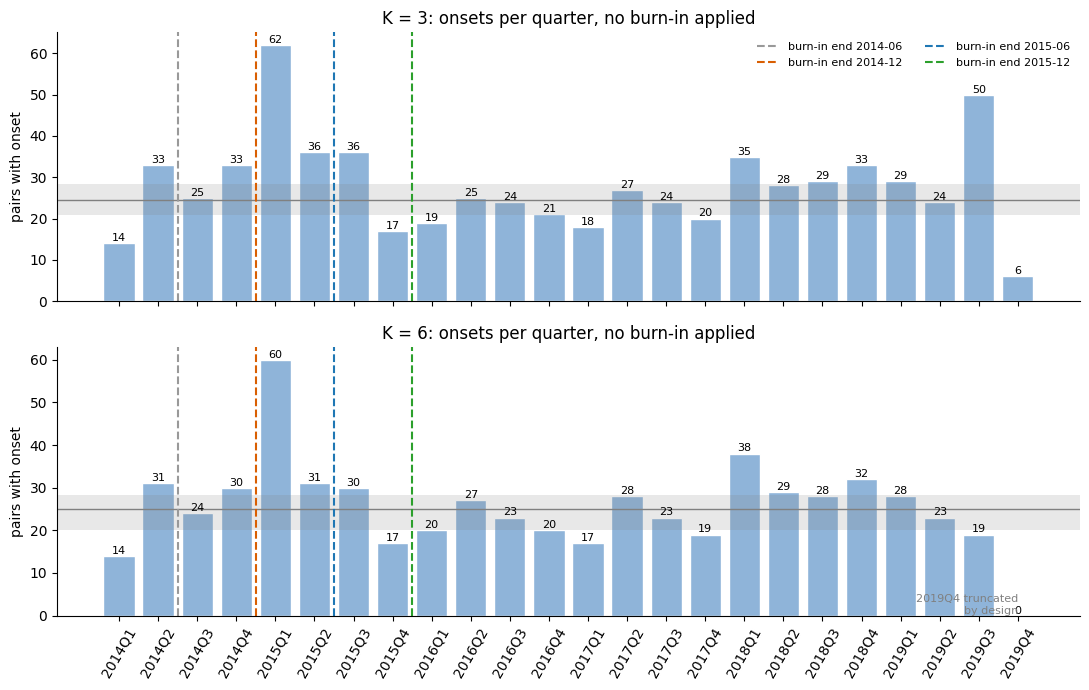

In [22]:
raw = {K: make_labels(g, months, K, burn_in_end="2013-12-01") for K in (3, 6)}   # burn-in off
allq = pd.period_range("2014Q1", "2019Q4", freq="Q")
cnt = {K: (raw[K][raw[K].status == "emerging"].onset_run.dt.to_period("Q")
           .value_counts().sort_index().reindex(allq, fill_value=0)) for K in raw}
print(pd.DataFrame({f"K={K}": cnt[K] for K in cnt}).T.to_string())

cand = {"2014-06": "#999999", "2014-12": "#d95f02", "2015-06": "#1f77b4", "2015-12": "#2ca02c"}
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for a_, K in zip(ax, (3, 6)):
    c = cnt[K]
    a_.bar(range(len(c)), c.values, color="#8fb4d9", edgecolor="white")
    steady = c.loc["2016Q1":"2018Q4"]
    a_.axhspan(steady.quantile(.25), steady.quantile(.75), color="grey", alpha=.18, lw=0)
    a_.axhline(steady.median(), color="grey", lw=1)
    for be, col in cand.items():
        x = c.index.get_loc(pd.Period(be, "Q")) + 0.5
        a_.axvline(x, ls="--", color=col, lw=1.5, label=f"burn-in end {be}")
    a_.set_ylabel("pairs with onset"); a_.set_title(f"K = {K}: onsets per quarter, no burn-in applied")
    for i, v in enumerate(c.values): a_.text(i, v + .5, str(v), ha="center", fontsize=8)
ax[0].legend(frameon=False, ncol=2, fontsize=8)
ax[1].set_xticks(range(len(allq))); ax[1].set_xticklabels(allq.astype(str), rotation=60)
ax[1].text(len(allq) - 1, 0.5, "2019Q4 truncated\nby design", ha="right", fontsize=8, color="grey")
save("08a_onsets_raw_by_quarter")

**Figure B** shows what each candidate burn-in does to the target (*K* = 3): blue = kept as emerging (positive class), grey = moved to burn-in control.

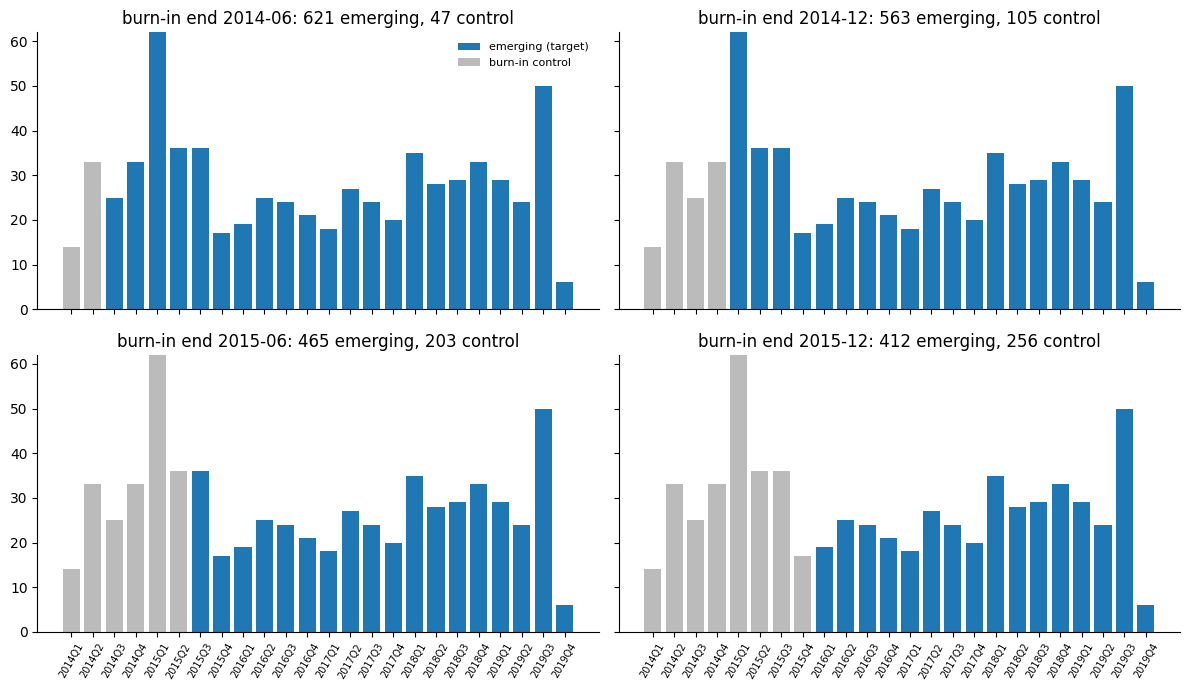

In [23]:
fig, ax = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
for a_, be in zip(ax.ravel(), ["2014-06-01", "2014-12-01", "2015-06-01", "2015-12-01"]):
    l = make_labels(g, months, 3, burn_in_end=be)
    l["q"] = l.onset_run.dt.to_period("Q")
    t = (l[l.status.isin(["emerging", "control_burn_in"])]
           .groupby(["q", "status"]).size().unstack(fill_value=0).reindex(allq, fill_value=0))
    for s in ("emerging", "control_burn_in"):
        if s not in t: t[s] = 0
    x = np.arange(len(t))
    a_.bar(x, t.emerging, color="#1f77b4", label="emerging (target)")
    a_.bar(x, t.control_burn_in, bottom=t.emerging, color="#bbbbbb", label="burn-in control")
    a_.set_title(f"burn-in end {be[:7]}: {int(t.emerging.sum())} emerging, {int(t.control_burn_in.sum())} control")
ax[0, 0].legend(frameon=False, fontsize=8)
for a_ in ax[1]:
    a_.set_xticks(range(len(allq))); a_.set_xticklabels(allq.astype(str), rotation=60, fontsize=7)
save("08b_burn_in_options")

**Table:** burn-in sensitivity at *K* = 3 (retains the 2014 settings alongside the 2015 ones).

In [24]:
rows = []
for be in ["2014-06-01", "2014-12-01", "2015-06-01", "2015-12-01"]:
    r = label_summary(3, be); r["burn_in_end"] = be[:7]; rows.append(r)
print(pd.DataFrame(rows).set_index("burn_in_end").drop(columns="K").to_string())

             emerging  control_burn_in  censored  never  emerging_not_strong_at_end  % transient  prevalence %
burn_in_end                                                                                                   
2014-06           621               47        13   2861                          59          9.5          17.8
2014-12           563              105        13   2861                          50          8.9          16.4
2015-06           465              203        13   2861                          33          7.1          14.0
2015-12           412              256        13   2861                          30          7.3          12.6


**Decision: burn-in = 2015-06 is primary; 2014-12 and 2015-12 are kept as sensitivity versions.**

* **2015Q1 is the clear start-up spike** (62 onsets, about twice the 18–35 per quarter seen from 2016 onwards, excluding the 2019Q3 cluster and the truncated 2019Q4). Burn-in ends of 2014-06 and 2014-12 keep it in the positive class (563 emerging at 2014-12).
* **2015-06 is the first candidate that removes the spike** and also the borderline quarter 2015Q2 (36). Cost: 98 positives (563 to 465); the remaining ones are cleaner. Prevalence is 465 / (465 + 2,861) = 14%.
* **2015Q3 (36) is still at the upper end** of the later range (2016–17: 18–27; 2018: 28–35), so 2015-06 may not fully clear the transition. Burn-in 2015-12 removes 53 more pairs (2015Q3 36 + 2015Q4 17), leaving a series in line with 2016–17 (44–45 per half-year against 53 for 2015H2), but costs more positives and shortens the at-risk window. It is therefore a sensitivity version, not the primary choice.
* This is a judgement call supported by Figures A and B, not by the table alone.

The 2019Q3 spike (50 onsets) is a separate matter, handled in Section 3.5.

### 3.5 Final label and saved files

**Frozen choices:** *K* = 3, burn-in 2015-06, censored pairs excluded, noise list as of the 613-signal run, full-precision prior from `ebgm_prior.csv`.

**Sensitivity labels saved for later use** (not yet evaluated in this notebook): *K* = 6, burn-in 2014-12, burn-in 2015-12. The label tables also contain `strong_at_end`, so the variant "emerging *and* still strong at the end" can be derived (432 of the 465 emerging pairs).

In [25]:
out = SIG_DIR
BURN = "2015-06-01"
labels = {}
for K in (3, 6):
    labels[K] = make_labels(g, months, K, burn_in_end=BURN)
    save_ = labels[K].copy()
    save_["ingredient"] = save_.pair.str[0]            # tuples don't survive CSV
    save_["pt"] = save_.pair.str[1]
    save_.drop(columns="pair").to_csv(out / f"onset_labels_K{K}_burn{BURN[:7]}.csv", index=False)
    print(f"K={K}, burn-in {BURN[:7]}")
    print(labels[K].status.value_counts())
    print(pd.crosstab(labels[K].status, labels[K].strong_at_end), "\n")

# burn-in sensitivity labels (K=3), so the 2014 version can be reloaded later
for be in ["2014-12-01", "2015-12-01"]:
    s_ = make_labels(g, months, 3, burn_in_end=be)
    s_["ingredient"] = s_.pair.str[0]; s_["pt"] = s_.pair.str[1]
    s_.drop(columns="pair").to_csv(out / f"onset_labels_K3_burn{be[:7]}.csv", index=False)

K=3, burn-in 2015-06
status
never              2861
emerging            465
control_burn_in     203
censored             13
Name: count, dtype: int64
strong_at_end    False  True 
status                       
censored             0     13
control_burn_in     35    168
emerging            33    432
never             2861      0 

K=6, burn-in 2015-06
status
never              2880
emerging            421
control_burn_in     190
censored             51
Name: count, dtype: int64
strong_at_end    False  True 
status                       
censored             0     51
control_burn_in     25    165
emerging            24    397
never             2880      0 



#### Quarterly onset counts of the final label (burn-in 2015-06)

In [26]:
# K=3
em = labels[3][labels[3].status == "emerging"].copy()
em["ingredient"] = em.pair.str[0]
print(len(em))                                   # expect 465
print(em.onset_run.dt.to_period("Q").value_counts().sort_index())
print(em.groupby("ingredient").size())

465
onset_run
2015Q3    36
2015Q4    17
2016Q1    19
2016Q2    25
2016Q3    24
2016Q4    21
2017Q1    18
2017Q2    27
2017Q3    24
2017Q4    20
2018Q1    35
2018Q2    28
2018Q3    29
2018Q4    33
2019Q1    29
2019Q2    24
2019Q3    50
2019Q4     6
Freq: Q-DEC, Name: count, dtype: int64
ingredient
canagliflozin    123
dapagliflozin     83
dulaglutide       44
empagliflozin     99
ertugliflozin     11
liraglutide       59
semaglutide       46
dtype: int64


In [27]:
# K=6
em = labels[6][labels[6].status == "emerging"].copy()
em["ingredient"] = em.pair.str[0]
print(len(em))                                   # expect 421
print(em.onset_run.dt.to_period("Q").value_counts().sort_index())
print(em.groupby("ingredient").size())

421
onset_run
2015Q3    30
2015Q4    17
2016Q1    20
2016Q2    27
2016Q3    23
2016Q4    20
2017Q1    17
2017Q2    28
2017Q3    23
2017Q4    19
2018Q1    38
2018Q2    29
2018Q3    28
2018Q4    32
2019Q1    28
2019Q2    23
2019Q3    19
Freq: Q-DEC, Name: count, dtype: int64
ingredient
canagliflozin    119
dapagliflozin     74
dulaglutide       44
empagliflozin     81
ertugliflozin      9
liraglutide       57
semaglutide       37
dtype: int64


**Sample size by drug.** For the primary label (*K* = 3) canagliflozin (123), empagliflozin (99) and dapagliflozin (83) have enough positives for separate analysis; liraglutide (59), semaglutide (46) and dulaglutide (44) are modest; ertugliflozin (11) is far too small to support any metric. (At *K* = 6: 9 for ertugliflozin and 37 for semaglutide.)

* **Design consequence:** one **pooled** model is fitted and evaluated across all drugs, with drug class (SGLT2 inhibitor vs GLP-1 receptor agonist) as a feature. Results by class are planned but not yet reported (Section 11).
* The positives are split across cutoffs: each cutoff only contains the positives whose onset falls in its 12-month window, so the effective number per cutoff is a fraction of these totals.
* Semaglutide and ertugliflozin were launched in early 2018 and so have only about two years of data. They enter the at-risk set late; a cutoff before 2018 contains none of them.

#### The 2019Q3 cluster of onsets

Quarter 2019Q3 has 50 onsets, well above the 18–35 of other quarters. We list all of them:

In [28]:
em = labels[3][labels[3].status == "emerging"].copy()
em["ingredient"] = em.pair.str[0]
em["pt"] = em.pair.str[1]
q = em[em.onset_run.dt.to_period("Q") == "2019Q3"]
print(len(q))                                  # expect 50
print(q.groupby("ingredient").size())
print(q.pt.tolist())  

50
ingredient
canagliflozin     5
dapagliflozin    10
empagliflozin    16
ertugliflozin     3
liraglutide       2
semaglutide      14
dtype: int64
['DIABETIC NEUROPATHY', 'GLUCOSE URINE ABSENT', 'STAPHYLOCOCCAL BACTERAEMIA', 'STAPHYLOCOCCAL SEPSIS', 'STREPTOCOCCAL SEPSIS', 'BLADDER DISORDER', 'BLADDER SPASM', 'BLADDER TRANSITIONAL CELL CARCINOMA', 'BLOOD CREATINE INCREASED', 'FUNGAL SEPSIS', 'GENITAL DISCHARGE', 'HYPERGLYCAEMIC HYPEROSMOLAR NONKETOTIC SYNDROME', 'INSULIN C-PEPTIDE DECREASED', 'NECROTISING SOFT TISSUE INFECTION', 'VULVOVAGINAL DISCOMFORT', 'CHROMATURIA', 'DIZZINESS', 'FASCIITIS', 'GENITAL BLISTER', 'GLUCOSE URINE', 'HAEMATURIA', 'HYPERGLYCAEMIA', 'MICTURITION FREQUENCY DECREASED', 'NECROTISING SOFT TISSUE INFECTION', 'PERINEAL INFECTION', 'PERINEAL RASH', 'SCROTAL ABSCESS', 'SEPSIS', 'TESTICULAR PAIN', 'URINARY INCONTINENCE', 'URINE ALCOHOL TEST POSITIVE', 'DYSURIA', "FOURNIER'S GANGRENE", 'VAGINAL INFECTION', 'BILE DUCT OBSTRUCTION', 'PARATHYROID TUMOUR BENIGN', 'ABDOM

**Decision.** The list contains many related terms (Fournier's gangrene and other soft-tissue infection and genital terms for the SGLT2 inhibitors, gastrointestinal terms for semaglutide), i.e. correlated onsets. A link to the Aug 2018 FDA communication (SGLT2 inhibitors) and to the recent launch of semaglutide is plausible but was not tested. The onsets are real under the rule fixed before any model was run, so they are **kept but flagged**. The design is unchanged. The 2019Q3 onsets affect only the last test cutoff (2018-09, whose horizon runs to Sep 2019), and Section 7.2 repeats the comparison without it.

**Figure C:** onsets per quarter for the final label (*K* = 3, burn-in 2015-06). Blue = emerging (target), grey = burn-in control.

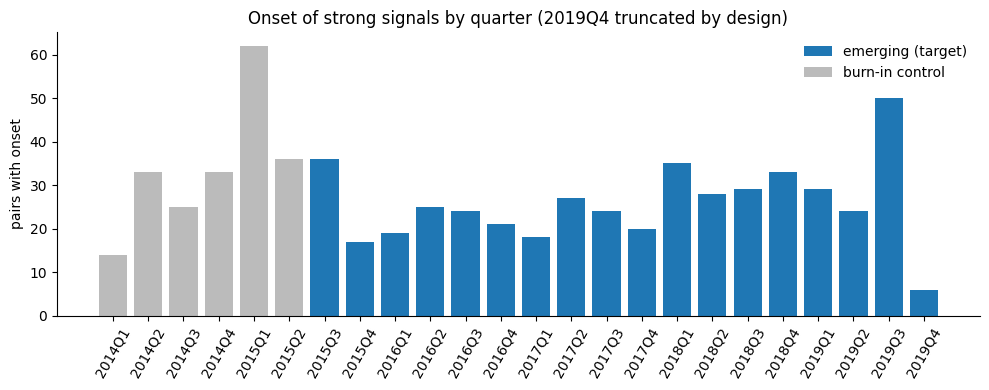

In [29]:
lab3 = make_labels(g, months, 3, burn_in_end="2015-06-01")
lab3["q"] = lab3.onset_run.dt.to_period("Q")
tab = lab3[lab3.status.isin(["emerging", "control_burn_in"])].groupby(["q", "status"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(tab))
ax.bar(x, tab.get("emerging", 0), color="#1f77b4", label="emerging (target)")
ax.bar(x, tab.get("control_burn_in", 0), bottom=tab.get("emerging", 0), color="#bbbbbb", label="burn-in control")
ax.set_xticks(x); ax.set_xticklabels(tab.index.astype(str), rotation=60)
ax.set_ylabel("pairs with onset"); ax.legend(frameon=False)
ax.set_title("Onset of strong signals by quarter (2019Q4 truncated by design)")
save("08_onsets")

### 3.6 What the final label means for the forecasting design

With *K* = 3 and burn-in 2015-06 the positives are the **465 emerging pairs** (432 if "still strong at the end" is also required). Pair-level prevalence is 465 / 3,326 = 14%. The prevalence at each walk-forward cutoff is much lower (about 2–6%) because only a fraction of the emerging pairs start within a given 12-month window; this lower figure is the chance level for average precision.

* Pairs enter the at-risk set only once *a* ≥ 3, so every prediction is conditional on a pair already having 3 reports.
* Onsets are spread over 2015Q3 to 2019Q3 rather than concentrated early, so a 12-month horizon is feasible.

We now have what the forecasting test needs: a monthly panel (`fc_pair_month_eb`, `signal_ts`), a frozen label and a validated EB pipeline.

## 4. Walk-forward evaluation design and the at-risk panel

### 4.1 Design

**Cutoffs.** 14 quarter-ends from Jun 2015 to Sep 2018. The last 7 (Mar 2017 – Sep 2018) are **test** cutoffs; earlier ones are used only for training.

**At-risk pairs at cutoff *t*.** Non-noise pairs that
* have *a* ≥ 3 at *t*;
* have **never been strong in any month up to *t*** (this also removes pairs that were strong for only one or two months);
* are not `control_burn_in` or `censored` in the final label.

**Label.** *y* = 1 if the pair's onset falls in (*t*, *t* + 12 months], else 0.

**Features** use only data up to *t*: log EB05 and EBGM, log report count (`la`), 3- and 6-month log growth in *a* (`da3`, `da6`), 3- and 6-month change in EB05 (`deb3`, `deb6`), months since the pair reached 3 reports (`months_since3`) and drug class (`sglt2`).

**Leakage control.** A label for cutoff *c* is only known once its onset run could have completed, i.e. at *c* + 12 + (*K* − 1) = *c* + 14 months. Models for test cutoff *t* are therefore trained only on cutoffs ≤ *t* − 14 months (`GAP = 14`). Two sources of mild look-ahead remain: the exclusion of `censored` and `control_burn_in` pairs uses full-sample labels, and the EBGM prior was fitted on data up to 2019 (Section 11).

**Metrics.** Average precision and recall in the top 5% per cutoff, averaged over cutoffs with equal weight. Intervals come from a **bootstrap that resamples pairs** (the same pair appears at several cutoffs); differences between methods are computed on the same resamples (*paired* bootstrap). Lead time (Section 8) is the number of months between a pair's first alert and its onset.

**Reference cases.** `ref_known_signal` lists FDA safety communications for ketoacidosis (May 2015), canagliflozin amputation (May 2016) and Fournier's gangrene (Aug 2018). The first two precede the first test cutoff (Mar 2017) and cannot be tested out of sample; Fournier's gangrene is the only reference case inside the test window (Section 8.4).

### 4.2 Build the at-risk panel with features

In [30]:
pm = con.sql("SELECT ingredient, pt, m, a FROM pair_month").df()
pm["m"] = pd.to_datetime(pm["m"])
pm["pair"] = list(zip(pm.ingredient, pm.pt))
pid_map = {p_: i for i, p_ in enumerate(pm.pair.unique())}
pm["pid"] = pm.pair.map(pid_map)
a_s = pm.set_index(["pid", "m"]).a
first3 = pm[pm.a >= 3].groupby("pid").m.min()

eb_s = g["EB05"].copy()
eb_s.index = pd.MultiIndex.from_arrays(
    [g.index.get_level_values("pair").map(pid_map), g.index.get_level_values("m")])

def lookup(s, pid, dates):
    return s.reindex(pd.MultiIndex.from_arrays([pid, dates])).values

def build_panel(cutoffs, H=12, burn_in_end="2015-06-01"):
    lab = make_labels(g, months, 3, burn_in_end=burn_in_end).set_index("pair")
    rows = []
    for t in cutoffs:
        gt = g.xs(t, level="m")
        ever = g[g.index.get_level_values("m") <= t].groupby(level="pair").strong.max()
        risk = gt[(gt.a >= 3) & ~gt.strong & ~ever.reindex(gt.index).fillna(False)].copy()
        risk = risk.join(lab[["onset_run", "status"]], how="left")
        risk = risk[risk.status.isin(["emerging", "never"])]
        risk["y"] = ((risk.status == "emerging") & (risk.onset_run > t) &
                     (risk.onset_run <= t + pd.DateOffset(months=H))).astype(int)
        risk["cutoff"] = t
        rows.append(risk.reset_index())
    d = pd.concat(rows, ignore_index=True)

    d["pid"] = d.pair.map(pid_map)
    d["sglt2"] = d.pair.str[0].isin(
        ["canagliflozin","dapagliflozin","empagliflozin","ertugliflozin"]).astype(int)
    a_t = lookup(a_s, d.pid, d.cutoff)
    d["la"] = np.log(a_t)
    for k in (3, 6):
        a_k = lookup(a_s, d.pid, d.cutoff - pd.DateOffset(months=k))
        d[f"da{k}"] = np.log1p(a_t) - np.log1p(a_k)          # log growth in reports
        d[f"deb{k}"] = d.EB05 - lookup(eb_s, d.pid, d.cutoff - pd.DateOffset(months=k))  # NaN if a<3 then
    f3 = d.pid.map(first3)
    d["months_since3"] = (d.cutoff.dt.year - f3.dt.year) * 12 + (d.cutoff.dt.month - f3.dt.month)
    d["lEB05"], d["lEBGM"] = np.log1p(d.EB05), np.log1p(d.EBGM)
    return d

cutoffs_q = pd.date_range("2015-06-01", "2018-09-01", freq="3MS")

panel = build_panel(cutoffs_q)
print(panel.groupby("cutoff").y.agg(["sum","size"]).T)     # positives and at-risk pairs per cutoff
print(panel[["la","da3","da6","deb3","deb6","months_since3"]].describe().T[["count","mean","min","max"]])

cutoff  2015-06-01  2015-09-01  2015-12-01  2016-03-01  2016-06-01  2016-09-01  2016-12-01  2017-03-01  2017-06-01  2017-09-01  2017-12-01  2018-03-01  2018-06-01  2018-09-01
sum             36          42          43          47          45          42          39          37          35          35          36          33          38          56
size           588         844         981        1075        1210        1366        1437        1536        1640        1759        1863        1989        2098        2264
                 count       mean       min        max
la             20650.0   2.032924  1.098612   6.248043
da3            20650.0   0.128962  0.000000   3.713572
da6            20650.0   0.275724  0.000000   3.912023
deb3           18660.0   0.017075 -1.076719   1.428611
deb6           16687.0   0.030757 -1.292743   1.599289
months_since3  20650.0  17.720291  0.000000  55.000000


In [31]:
# Guard against silent drift: the panel and labels must reproduce the frozen counts

assert g.shape[0] == 3542 * 72
assert sig[~sig.is_noise].strong.sum() == 613
lab3 = make_labels(g, months, 3, "2015-06-01")
assert lab3.status.value_counts().to_dict() == {"never": 2861, "emerging": 465,
                                                "control_burn_in": 203, "censored": 13}
panel = build_panel(cutoffs_q)
assert panel.groupby("cutoff").y.sum().iloc[0] == 36

## 5. Baseline (Arm A): EB05 at the cutoff

Score each at-risk pair by its EB05 at the cutoff. The report count *a* alone is evaluated as a negative control. For each cutoff we report average precision (AP), lift over prevalence, and recall among the 50 top-ranked pairs and among the top 5%. This tests whether current disproportionality already predicts emergence.

In [32]:
def eval_cut(d, score, top_n=50, top_pct=0.05):
    d = d.sort_values(score, ascending=False)
    k_pct = max(1, int(round(top_pct * len(d))))
    pos = d.y.sum()
    return pd.Series({
        "n": len(d), "pos": pos, "prev": pos / len(d),
        "ap": average_precision_score(d.y, d[score]),
        "lift": average_precision_score(d.y, d[score]) / (pos / len(d)),
        f"recall@{top_n}": d.y.head(top_n).sum() / pos,
        f"recall@{int(top_pct*100)}%": d.y.head(k_pct).sum() / pos,
    })

for s in ["EB05", "a"]:
    print(s)
    print(panel.groupby("cutoff")
               .apply(lambda d: eval_cut(d, s), include_groups=False)
               .round(3))

EB05
                 n   pos   prev     ap    lift  recall@50  recall@5%
cutoff                                                              
2015-06-01   588.0  36.0  0.061  0.245   3.995      0.278      0.250
2015-09-01   844.0  42.0  0.050  0.496   9.960      0.524      0.452
2015-12-01   981.0  43.0  0.044  0.609  13.886      0.558      0.558
2016-03-01  1075.0  47.0  0.044  0.420   9.595      0.426      0.426
2016-06-01  1210.0  45.0  0.037  0.408  10.972      0.444      0.467
2016-09-01  1366.0  42.0  0.031  0.296   9.619      0.381      0.524
2016-12-01  1437.0  39.0  0.027  0.297  10.948      0.436      0.513
2017-03-01  1536.0  37.0  0.024  0.431  17.897      0.432      0.568
2017-06-01  1640.0  35.0  0.021  0.447  20.959      0.543      0.543
2017-09-01  1759.0  35.0  0.020  0.428  21.486      0.486      0.571
2017-12-01  1863.0  36.0  0.019  0.361  18.665      0.389      0.583
2018-03-01  1989.0  33.0  0.017  0.266  16.063      0.273      0.515
2018-06-01  2098.0  38.0  0.0

**Result 1: EB05 is a strong baseline; the report count alone is not.**

| | EB05 | *a* (count only) |
|---|---|---|
| Lift over prevalence | 4.0 to 21.5 (mostly 10–21) | 0.8 to 1.5 |
| AP | 0.25 to 0.61 | 0.015 to 0.077 |
| Recall in top 5% | 0.25 to 0.58 | 0.00 to 0.12 |

The report count alone does nothing (lift about 1 is chance level). EB05 gives roughly 10–21× lift at most cutoffs. Because prevalence is low, absolute AP is moderate, but about half of the future emergences are in the top 5% of the at-risk set. This is the bar the other arms have to clear.

**Result 2: reading the pattern**

* The first cutoff (2015-06) is the weakest (lift 4.0, recall@50 0.28). This fits the warm-up concern: accumulation from the empty 2014 start makes early EB05 less informative. It is reported with the others but could be dropped from a pooled average.
* Lift rises from about 10 in 2016 to 18–21 in 2017 mainly because prevalence falls while AP stays roughly 0.3–0.45. AP and recall are more comparable across cutoffs than lift.
* Performance dips at 2018-03 and 2018-06 (AP 0.27–0.30, recall@50 0.27–0.37). The cause is unknown; one hypothesis is that reporting dynamics changed after the Aug 2018 FDA communication, but that is a hypothesis, not a finding.
* Recall@50 and recall@5% diverge as the at-risk set grows (5% of 2,264 pairs is 113), so recall@5% is the better measure across cutoffs.
* The 2018-09 cutoff contains the 2019Q3 cluster. Its recall@5% (0.54) is in line with its neighbours, but results are also reported without it (Section 7.2).

**Cautions**

* The prior is fitted on 2019 data, which may help early EB05 slightly (leakage; Section 11).
* Counts per cutoff are small (33–56 positives), so single-cutoff differences of 0.05 in recall are within noise. Judge methods by the pooled result with a pair-level bootstrap.

### Pooled baseline with bootstrap intervals

Pool all 14 cutoffs with equal weight and bootstrap by pair (1,000 resamples).

In [33]:
# First, one pooled summary, weighting each cutoff equally, with the bootstrap by pair:
# Pooled Arm A: the baseline numbers
pairs = panel.pair.unique()
rng = np.random.default_rng(0)

def pooled(d, score="EB05", pct=0.05):
    out = []
    for _, x in d.groupby("cutoff"):
        if x.y.sum() == 0: continue
        k = max(1, int(round(pct * len(x))))
        xs = x.sort_values(score, ascending=False)
        out.append((average_precision_score(x.y, x[score]), xs.y.head(k).sum() / x.y.sum()))
    return np.mean(out, axis=0)

base = pooled(panel)
boots = []
for _ in range(1000):
    samp = rng.choice(pairs, len(pairs), replace=True)
    boots.append(pooled(panel.merge(pd.DataFrame({"pair": samp}), on="pair")))
print(base, np.percentile(boots, [2.5, 97.5], axis=0))

[0.3815793  0.50414522] [[0.33208872 0.44540999]
 [0.44012984 0.56050406]]


**Pooled Arm A (EB05 at the cutoff, 14 cutoffs, 2015-06 to 2018-09)**

* **Average precision: 0.38** (95% bootstrap interval 0.33 to 0.44).
* **Recall in the top 5% of the watch list: 0.50** (0.45 to 0.56). A random 5% would catch about 5%.

How to read it: current disproportionality already predicts emergence well, and the per-cutoff lift over chance ranges from 4 to 21 (median about 14). AP is moderate in absolute terms because positives are rare at each cutoff.

This is **not** the table used for the method comparison from Section 6 onwards, which uses only the 7 test cutoffs from 2017-03 (EB05: AP 0.37, recall@5% 0.55).

Cautions: the first cutoff (2015-06) is the weakest (AP 0.25); the prior was fitted on 2019 data; and the bootstrap ignores correlation between consecutive cutoffs, so the true uncertainty is wider than the intervals shown.

## 6. Machine-learning models (Arm B)

Arm B combines EB05 with features describing the pair's reporting history (see Section 4.1), in two models:

* **B1:** logistic regression (median imputation, standardisation, L2 penalty, C = 0.5);
* **B2:** gradient boosting (`HistGradientBoostingClassifier`, depth 3, learning rate 0.05, 200 iterations).

Both are trained walk-forward: for each test cutoff the training data are the cutoffs at least 14 months earlier (Section 4.1). Together with the features, this tests whether *recent trend and history* add information beyond today's EB05, which is the premise behind forecasting. These are features derived from the same EB05 history, not forecasts (those follow in Section 9).

### 6.1 Walk-forward training

In [34]:
warnings.filterwarnings("ignore", category=RuntimeWarning)

FEATS = ["lEB05","lEBGM","la","da3","da6","deb3","deb6","months_since3","sglt2"]
GAP = 14                                   # H (12) + K-1 (2) months until a label is known
test_cuts = [c for c in cutoffs_q if c >= pd.Timestamp("2017-03-01")]

parts = []
for t in test_cuts:
    tr = panel[panel.cutoff <= t - pd.DateOffset(months=GAP)]
    te = panel[panel.cutoff == t].copy()
    lr = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                       LogisticRegression(C=0.5, max_iter=2000))
    gb = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200,
                                        min_samples_leaf=30, l2_regularization=1.0, random_state=0)
    lr.fit(tr[FEATS], tr.y); gb.fit(tr[FEATS], tr.y)
    te["p_lr"] = lr.predict_proba(te[FEATS])[:, 1]
    te["p_gb"] = gb.predict_proba(te[FEATS])[:, 1]
    print(t.date(), "train cutoffs:", tr.cutoff.nunique(), "| train pos:", int(tr.y.sum()), "| rows:", len(tr))
    parts.append(te)
test = pd.concat(parts, ignore_index=True)

2017-03-01 train cutoffs: 3 | train pos: 121 | rows: 2413
2017-06-01 train cutoffs: 4 | train pos: 168 | rows: 3488
2017-09-01 train cutoffs: 5 | train pos: 213 | rows: 4698
2017-12-01 train cutoffs: 6 | train pos: 255 | rows: 6064
2018-03-01 train cutoffs: 7 | train pos: 294 | rows: 7501
2018-06-01 train cutoffs: 8 | train pos: 331 | rows: 9037
2018-09-01 train cutoffs: 9 | train pos: 366 | rows: 10677


Sanity check: are feature values and predicted probabilities in a sensible range? (Numerical `RuntimeWarning`s from the fits are suppressed above.)

In [35]:
print(panel[FEATS].describe().T[["min","max","std"]])

# 2. Is the model output sane despite the warnings?
print(test[["p_lr","p_gb"]].describe().T[["count","min","max"]])
print(test.p_lr.isna().sum(), np.isinf(test.p_lr).sum())

                    min        max        std
lEB05          0.007965   1.096733   0.208099
lEBGM          0.021437   2.515621   0.339093
la             1.098612   6.248043   0.946513
da3            0.000000   3.713572   0.226536
da6            0.000000   3.912023   0.360439
deb3          -1.076719   1.428611   0.096680
deb6          -1.292743   1.599289   0.131952
months_since3  0.000000  55.000000  12.398200
sglt2          0.000000   1.000000   0.490892
        count       min       max
p_lr  13149.0  0.000023  0.979460
p_gb  13149.0  0.000059  0.886625
0 0


### 6.2 Results: pooled metrics, paired bootstrap and per-cutoff AP

Pooled over the 7 test cutoffs, with 95% intervals from a bootstrap by pair (200 resamples). The `B − A` lines are paired differences versus EB05.

In [36]:
scores = {"A: EB05": "EB05", "B1: logistic": "p_lr", "B2: boosting": "p_gb"}
base = {k: pooled(test, s) for k, s in scores.items()}

rng = np.random.default_rng(0)
pids = test.pid.unique()
boot = {k: [] for k in scores}
for _ in range(200):
    samp = test.merge(pd.DataFrame({"pid": rng.choice(pids, len(pids), replace=True)}), on="pid")
    for k, s in scores.items():
        boot[k].append(pooled(samp, s))
boot = {k: np.array(v) for k, v in boot.items()}

rows = []
for k in scores:
    ci = np.percentile(boot[k], [2.5, 97.5], axis=0)
    rows.append([k, base[k][0], ci[0,0], ci[1,0], base[k][1], ci[0,1], ci[1,1]])
print(pd.DataFrame(rows, columns=["arm","AP","AP_lo","AP_hi","rec5","rec5_lo","rec5_hi"]).round(3))

for k in ["B1: logistic", "B2: boosting"]:           # paired differences vs Arm A
    dlt = boot[k] - boot["A: EB05"]
    print(k, "- A | AP diff", dlt[:,0].mean().round(3), np.percentile(dlt[:,0], [2.5,97.5]).round(3),
          "| recall@5% diff", dlt[:,1].mean().round(3), np.percentile(dlt[:,1], [2.5,97.5]).round(3))

print(test.groupby("cutoff").apply(lambda x: pd.Series({s: average_precision_score(x.y, x[s])
      for s in ["EB05","p_lr","p_gb"]}), include_groups=False).round(3))

            arm     AP  AP_lo  AP_hi   rec5  rec5_lo  rec5_hi
0       A: EB05  0.368  0.302  0.446  0.553    0.476    0.645
1  B1: logistic  0.443  0.369  0.542  0.733    0.650    0.806
2  B2: boosting  0.433  0.390  0.512  0.697    0.628    0.760
B1: logistic - A | AP diff 0.079 [-0.012  0.161] | recall@5% diff 0.183 [0.101 0.272]
B2: boosting - A | AP diff 0.073 [0.014 0.133] | recall@5% diff 0.144 [0.057 0.244]
             EB05   p_lr   p_gb
cutoff                         
2017-03-01  0.431  0.383  0.343
2017-06-01  0.447  0.488  0.480
2017-09-01  0.428  0.397  0.450
2017-12-01  0.361  0.346  0.452
2018-03-01  0.266  0.455  0.449
2018-06-01  0.299  0.455  0.355
2018-09-01  0.340  0.581  0.505


**Result.**

* **Recall in the top 5% improves clearly for both models.** Both intervals of the difference exclude zero. About 70–73% of the pairs that emerge within 12 months are in the top 5% under B, against 55% under EB05 alone. That is a real gain at a practical alert budget.
* **AP improves, but only B2's interval excludes zero.** B1's AP interval just includes zero (−0.012), so for AP the evidence is suggestive, not conclusive. We do not claim that B1 beats A on AP.
* **B1 and B2 are similar** (the difference between them was not tested directly), which suggests the gain comes from the features, not from model flexibility. The logistic model is the easier one to defend.
* **The gain is concentrated in 2018.** In 2017, A and B are similar and B1 is sometimes lower (2017-03, 2017-09, 2017-12). From 2018-03 on B is clearly better (0.27 → 0.45, 0.30 → 0.36–0.46, 0.34 → 0.51–0.58). With 7 mostly overlapping cutoffs a few cutoffs drive the pooled mean; Section 7.2 repeats the comparison without the last cutoff.

## 7. Robustness checks

### 7.1 Logistic-regression solver

Does the choice of optimiser matter? We compare `lbfgs` (used above) with `liblinear` (used in the tuning code below), AP per cutoff.

In [37]:
def run_lr(solver):
    out = []
    for t in test_cuts:
        tr = panel[panel.cutoff <= t - pd.DateOffset(months=GAP)]
        te = panel[panel.cutoff == t]
        m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                          LogisticRegression(C=0.5, max_iter=2000, solver=solver))
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m.fit(tr[FEATS], tr.y)
        out.append(average_precision_score(te.y, m.predict_proba(te[FEATS])[:, 1]))
    return np.array(out)

print(np.round(run_lr("lbfgs"), 3))
print(np.round(run_lr("liblinear"), 3))

[0.383 0.488 0.397 0.346 0.455 0.455 0.581]
[0.385 0.492 0.396 0.346 0.459 0.455 0.58 ]


**Result:** the two solvers agree to within 0.004 at every cutoff, and the `lbfgs` values equal the `p_lr` column of the per-cutoff table above (0.383, 0.488, 0.397, …). Small differences between pooled numbers in later sections (for example 0.443 vs 0.445 AP for the default logistic model) come from this solver choice.

### 7.2 Excluding the last cutoff (2018-09)

The 2018-09 cutoff is the only one whose horizon contains the 2019Q3 cluster of correlated onsets. We repeat the pooled comparison without it and add the paired bootstrap (500 resamples). An interval that excludes zero means the gain holds without 2018-09.

In [38]:
# Drop the 2018-09 cutoff (its horizon contains the 2019Q3 cluster)
t2 = test[test.cutoff <"2018-09-01"]
for k, s in {"A": "EB05", "B1": "p_lr", "B2": "p_gb"}.items():
    print(k, np.round(pooled(t2, s), 3))

A [0.372 0.555]
B1 [0.42  0.721]
B2 [0.421 0.685]


In [39]:
rng = np.random.default_rng(0)
pids = t2.pid.unique()
boot2 = {k: [] for k in ["EB05", "p_lr", "p_gb"]}
for _ in range(500):
    s_ = t2.merge(pd.DataFrame({"pid": rng.choice(pids, len(pids), replace=True)}), on="pid")
    for k in boot2:
        boot2[k].append(pooled(s_, k))
boot2 = {k: np.array(v) for k, v in boot2.items()}

for k in ["p_lr", "p_gb"]:
    d_ = boot2[k] - boot2["EB05"]
    print(k, "- EB05 | AP diff", np.percentile(d_[:, 0], [2.5, 97.5]).round(3),
          "| recall@5% diff", np.percentile(d_[:, 1], [2.5, 97.5]).round(3))

p_lr - EB05 | AP diff [-0.041  0.156] | recall@5% diff [0.075 0.256]
p_gb - EB05 | AP diff [-0.014  0.118] | recall@5% diff [0.033 0.211]


**Result (6 test cutoffs, 2017-03 to 2018-06)**

| | AP | Recall in top 5% |
|---|---|---|
| A: EB05 | 0.372 | 0.555 |
| B1: logistic | 0.420 | 0.721 |
| B2: boosting | 0.421 | 0.685 |

* **The recall gain holds without 2018-09.** Point estimates are about +0.17 (B1) and +0.13 (B2), and both 95% intervals are above zero ([0.075, 0.256] and [0.033, 0.211]). This is the robust finding.
* **The AP gain is not established.** With all 7 cutoffs B2's AP interval excluded zero; now both intervals include it, so part of the AP advantage came from the 2018-09 cutoff and the correlated 2019Q3 onsets.
* The intervals are wide (six overlapping cutoffs, fewer than 130 distinct positive pairs), and the pair bootstrap ignores correlation between consecutive cutoffs, so the true uncertainty is somewhat wider still.

### 7.3 Hyperparameter tuning of the logistic model

Two analyses, neither used to select the reported model:

1. **Sensitivity grid (diagnostic).** 28 settings of C (0.01 to 10), penalty (L1, L2) and class weighting, evaluated on all 7 test cutoffs. Because the best setting on these cutoffs would be optimistic, this is not used for selection.
2. **Nested walk-forward tuning (leakage-safe).** At each test cutoff, settings are chosen using only earlier cutoffs whose labels are already known (selection score = mean of AP and recall@5%).

In [40]:
# Set-up for tuning the logistic model
GAPO = pd.DateOffset(months=GAP)

# simplest / most regularised first, so ties go to the simpler model
GRID = [dict(C=C, penalty=pen, class_weight=cw)
        for C in [0.01, 0.03, 0.1, 0.3, 1, 3, 10]
        for pen in ["l2", "l1"]
        for cw in [None, "balanced"]]
DEFAULT = dict(C=0.5, penalty="l2", class_weight=None)      # our current model

def fit_predict(tr, te, p, feats=FEATS):
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                      LogisticRegression(C=p["C"], penalty=p["penalty"],
                                         class_weight=p["class_weight"],
                                         solver="liblinear", max_iter=2000))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m.fit(tr[feats], tr.y)
    return m.predict_proba(te[feats])[:, 1]

def cut_metrics(x, pr, pct=0.05):
    k = max(1, int(round(pct * len(x))))
    rec = x.assign(p=pr).sort_values("p", ascending=False).y.head(k).sum() / x.y.sum()
    return average_precision_score(x.y, pr), rec

In [41]:
# Sensitivity grid (diagnostic only, not used for selection)
rows = []
for p in GRID:
    parts = []
    for t in test_cuts:
        tr = panel[panel.cutoff <= t - GAPO]
        te = panel[panel.cutoff == t].copy()
        te["p"] = fit_predict(tr, te, p)
        parts.append(te)
    ap, rec = pooled(pd.concat(parts), "p")
    rows.append({**p, "AP": round(ap, 3), "recall@5%": round(rec, 3)})
sens = pd.DataFrame(rows).sort_values("recall@5%", ascending=False)
print(sens.to_string(index=False))

    C penalty class_weight    AP  recall@5%
 0.03      l2         None 0.445      0.756
 0.03      l1         None 0.426      0.751
 0.10      l2         None 0.444      0.745
 0.01      l2         None 0.447      0.744
 0.30      l2         None 0.443      0.741
 0.10      l1         None 0.440      0.741
 0.01      l2     balanced 0.426      0.734
10.00      l1         None 0.443      0.733
 3.00      l1         None 0.442      0.733
 3.00      l2         None 0.442      0.733
 1.00      l1         None 0.443      0.733
 1.00      l2         None 0.442      0.733
 0.30      l1         None 0.442      0.733
10.00      l2         None 0.443      0.729
 0.01      l1     balanced 0.392      0.728
 0.03      l1     balanced 0.408      0.718
 0.10      l1     balanced 0.417      0.717
 0.10      l2     balanced 0.418      0.714
 0.03      l2     balanced 0.420      0.714
 3.00      l2     balanced 0.417      0.714
 3.00      l1     balanced 0.417      0.714
10.00      l2     balanced 0.417

In [42]:
# Nested, leakage-safe tuning

def tune_at(t, grid=GRID, feats=FEATS, min_inner=2):
    """Pick hyperparameters for test cutoff t using only cutoffs whose labels are known by t."""
    avail = panel[panel.cutoff <= t - GAPO]
    vcuts = [pd.Timestamp(v) for v in sorted(avail.cutoff.unique())
             if (avail.cutoff <= pd.Timestamp(v) - GAPO).any()]
    if len(vcuts) < min_inner:
        return DEFAULT, np.nan                       # too little history: keep default
    res = []
    for p in grid:
        sc = []
        for v in vcuts:
            tr_in = avail[avail.cutoff <= v - GAPO]
            va = avail[avail.cutoff == v]
            if tr_in.y.sum() == 0 or va.y.sum() == 0: continue
            ap, rec = cut_metrics(va, fit_predict(tr_in, va, p, feats))
            sc.append(0.5 * ap + 0.5 * rec)          # selection score: mean of AP and recall@5%
        res.append((np.mean(sc), p))
    best = max(res, key=lambda r: r[0])
    return best[1], best[0]

parts, chosen = [], []
for t in test_cuts:
    p_best, sc = tune_at(t)
    tr = panel[panel.cutoff <= t - GAPO]
    te = panel[panel.cutoff == t].copy()
    te["p_default"] = fit_predict(tr, te, DEFAULT)
    te["p_tuned"] = fit_predict(tr, te, p_best)
    chosen.append({"cutoff": t.date(), **p_best, "inner_score": round(sc, 3)})
    parts.append(te)
tuned = pd.concat(parts, ignore_index=True)
print(pd.DataFrame(chosen).to_string(index=False))

print("default", np.round(pooled(tuned, "p_default"), 3),
      "| tuned", np.round(pooled(tuned, "p_tuned"), 3))

rng = np.random.default_rng(0); pids_ = tuned.pid.unique()
bt = {k: [] for k in ["p_default", "p_tuned"]}
for _ in range(500):
    x = tuned.merge(pd.DataFrame({"pid": rng.choice(pids_, len(pids_), replace=True)}), on="pid")
    for k in bt: bt[k].append(pooled(x, k))
d = np.array(bt["p_tuned"]) - np.array(bt["p_default"])
print("tuned - default | AP", np.percentile(d[:, 0], [2.5, 97.5]).round(3),
      "| recall@5%", np.percentile(d[:, 1], [2.5, 97.5]).round(3))

    cutoff    C penalty class_weight  inner_score
2017-03-01 0.50      l2         None          NaN
2017-06-01 0.50      l2         None          NaN
2017-09-01 0.50      l2         None          NaN
2017-12-01 0.50      l2         None          NaN
2018-03-01 0.01      l1     balanced        0.500
2018-06-01 0.01      l2         None        0.523
2018-09-01 0.01      l2         None        0.551
default [0.445 0.737] | tuned [0.43  0.728]
tuned - default | AP [-0.03  0.  ] | recall@5% [-0.033  0.015]


**Result**

*Sensitivity grid.* Recall in the top 5% ranges from 0.70 to 0.76 and AP from 0.37 to 0.45. Every setting with C ≥ 0.3 and no class weighting is essentially identical (recall 0.73–0.74, AP about 0.44), and the default (C = 0.5) lies on this plateau. Balanced class weights lower AP (about 0.42) without helping recall, and very strong L1 regularisation underfits. The best grid value (recall 0.756, C = 0.03) is the best of 28 trials on the same test cutoffs, so it is optimistic and is not used.

*Nested tuning.* Tuning was possible only for the last three cutoffs; the first four used the default. Pooled over the 7 cutoffs: default AP 0.445, recall@5% 0.737; tuned AP 0.430, recall@5% 0.728. Paired bootstrap differences (tuned − default): AP [−0.03, 0.00], recall@5% [−0.033, 0.015]. **Tuning did not improve performance.**

**Conclusion:** the logistic model is not sensitive to its regularisation settings. The default model (L2, C = 0.5) is kept as B1 and tuning is reported as a robustness check. (The default here uses the `liblinear` solver, hence 0.445 / 0.737 rather than the 0.443 / 0.733 of Section 6.)

**Limitations:** inner validation used only a few cutoffs, so the chosen settings are noisy; tuning acted on 3 of 7 test cutoffs; the bootstrap does not account for correlation between cutoffs. The boosting model (B2) was not tuned.

### 7.4 Which features matter?

#### Logistic coefficients

Coefficients (on standardised features) of the logistic model fitted on the last training window (used for the 2018-09 test cutoff).

In [43]:
tr = panel[panel.cutoff <= pd.Timestamp("2018-09-01") - pd.DateOffset(months=GAP)]
m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                  LogisticRegression(C=0.5, max_iter=2000)).fit(tr[FEATS], tr.y)
print(pd.Series(m[-1].coef_[0], index=FEATS).sort_values().round(2))

months_since3   -0.53
la              -0.44
sglt2           -0.18
deb3             0.02
da3              0.04
deb6             0.05
da6              0.09
lEBGM            0.50
lEB05            1.37
dtype: float64


**Reading the coefficients.** EB05 dominates (1.37, plus 0.50 for EBGM). Conditional on EB05, a larger report count and an older pair (more months since 3 reports) both *lower* the predicted probability (−0.44 and −0.53), and SGLT2 membership is slightly negative (−0.18). The growth features (`da3`, `da6`, `deb3`, `deb6`) are close to zero (0.02 to 0.09). EB05 and EBGM are strongly related, so their individual weights should not be interpreted separately. The next check tests the contribution of each feature group directly.

#### Ablation: level and age versus growth

Three nested feature sets in the same walk-forward logistic model:

* **S0:** EB05 only;
* **S1:** + report count, pair age, drug class (and EBGM) — "level and age";
* **S2:** + growth features (all features, = B1).

Paired bootstrap (500 resamples) of S1 − S0 and S2 − S1.

In [44]:
def walk(feats):
    parts = []
    for t in test_cuts:
        tr = panel[panel.cutoff <= t - pd.DateOffset(months=GAP)]
        te = panel[panel.cutoff == t].copy()
        m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                          LogisticRegression(C=0.5, max_iter=2000)).fit(tr[feats], tr.y)
        te["p"] = m.predict_proba(te[feats])[:, 1]
        parts.append(te)
    return pd.concat(parts)

sets = {"S0 EB05 only": ["lEB05"],
        "S1 level + age": ["lEB05", "lEBGM", "la", "months_since3", "sglt2"],
        "S2 + growth": FEATS}
for name, f in sets.items():
    print(name, np.round(pooled(walk(f), "p"), 3))   # AP, recall@5%

S0 EB05 only [0.368 0.553]
S1 level + age [0.434 0.726]
S2 + growth [0.443 0.733]


In [45]:
w0, w1, w2 = (walk(f) for f in sets.values())          # same rows, same order
ab = w0[["pid", "cutoff", "y"]].copy()
ab["s0"], ab["s1"], ab["s2"] = w0.p.values, w1.p.values, w2.p.values

rng = np.random.default_rng(0)
pids = ab.pid.unique()
bs = {k: [] for k in ["s0", "s1", "s2"]}
for _ in range(500):
    x = ab.merge(pd.DataFrame({"pid": rng.choice(pids, len(pids), replace=True)}), on="pid")
    for k in bs:
        bs[k].append(pooled(x, k))
bs = {k: np.array(v) for k, v in bs.items()}

for name, a, b in [("S1 - S0 (level + age)", "s1", "s0"), ("S2 - S1 (growth)", "s2", "s1")]:
    d = bs[a] - bs[b]
    print(name, "| AP", np.percentile(d[:, 0], [2.5, 97.5]).round(3),
          "| recall@5%", np.percentile(d[:, 1], [2.5, 97.5]).round(3))

S1 - S0 (level + age) | AP [-0.027  0.16 ] | recall@5% [0.091 0.267]
S2 - S1 (growth) | AP [-0.002  0.021] | recall@5% [-0.021  0.034]


**Result.** A logistic model with EB05 plus report count, pair age and drug class (S1) catches about 17 percentage points more of the later signals in the top 5% than EB05 alone (recall 0.726 vs 0.553; interval of the difference [0.09, 0.27]). The AP gain (0.434 vs 0.368) is not established (interval [−0.03, 0.16]). Adding recent growth in reports and EB05 (S2) does not improve this further (changes below 0.01; intervals include zero). **The benefit therefore comes from the level and age of the pair, not from its short-term trend.**

## 8. Lead time, early detection and case studies

Beyond ranking quality we ask two practical questions at the same alert budget (top 5% per cutoff):

1. How many of the pairs that later became strong signals were on the watch list *at least once* in the 12 months before onset ("flagged early")?
2. How many months before onset was the first alert ("lead time")?

### 8.1 Flagged early and lead time

In [46]:
def lead_times(d, score, pct=0.05):
    d = d.copy()
    # rank each pair within its cutoff; top 5% = "alert"
    d["alert"] = d.groupby("cutoff")[score].rank(ascending=False, pct=True) <= pct
    # pairs that really became signals within 12 months of the cutoff
    real = d[d.y == 1]
    n_real = real.pid.nunique()
    # first cutoff at which each of them was alerted
    first = real[real.alert].sort_values("cutoff").groupby("pid").first()
    lead = ((first.onset_run.dt.year - first.cutoff.dt.year) * 12
            + (first.onset_run.dt.month - first.cutoff.dt.month))
    return pd.Series({"pairs that became signals": n_real,
                      "flagged early": len(first),
                      "% flagged early": round(100 * len(first) / n_real, 1),
                      "median months early": lead.median(),
                      "average months early": round(lead.mean(), 1)})

print(pd.DataFrame({"DPA only (EB05)": lead_times(test, "EB05"),
                    "Logistic regression": lead_times(test, "p_lr"),
                    "Boosting": lead_times(test, "p_gb")}))

                           DPA only (EB05)  Logistic regression  Boosting
pairs that became signals            127.0                127.0     127.0
flagged early                         87.0                109.0     107.0
% flagged early                       68.5                 85.8      84.3
median months early                    5.0                  7.0       6.0
average months early                   6.0                  6.8       6.5


Precision at the same alert budget. Alerts are counted per pair and cutoff, so one pair can be counted up to four times and an alert that is "wrong" may still turn into a signal later.

In [47]:
d = test.copy()
for s in ["EB05", "p_lr", "p_gb"]:
    d["alert_" + s] = d.groupby("cutoff")[s].rank(ascending=False, pct=True) <= 0.05
    a_ = d[d["alert_" + s]]
    print(s, "alerts:", len(a_), "| true signals within 12 months:", int(a_.y.sum()),
          "| precision:", round(a_.y.mean(), 3))

EB05 alerts: 654 | true signals within 12 months: 149 | precision: 0.228
p_lr alerts: 654 | true signals within 12 months: 199 | precision: 0.304
p_gb alerts: 654 | true signals within 12 months: 188 | precision: 0.287


### 8.2 Uncertainty: bootstrap of the lead-time comparison

One row per pair (positive pairs only), then bootstrap by pair (1,000 resamples) for the share flagged early and the median lead time.

In [48]:
S = ["EB05", "p_lr", "p_gb"]

def per_pair(d, scores=S, pct=0.05):
    d = d.copy()
    for s in scores:                                   # alert = top 5% within each cutoff
        d["alert_" + s] = d.groupby("cutoff")[s].rank(ascending=False, pct=True) <= pct
    d["months_to_onset"] = ((d.onset_run.dt.year - d.cutoff.dt.year) * 12
                            + (d.onset_run.dt.month - d.cutoff.dt.month))
    rows = []
    for pid, x in d.groupby("pid"):
        xp = x[x.y == 1].sort_values("cutoff")         # only the cutoffs where this pair was a true positive
        r = {"pid": pid, "pos": len(xp) > 0}
        for s in scores:
            hit = xp[xp["alert_" + s]]
            r["flag_" + s] = len(hit) > 0                                   # flagged early at least once
            r["lead_" + s] = hit.months_to_onset.iloc[0] if len(hit) else np.nan   # months early, first alert
        rows.append(r)
    return pd.DataFrame(rows)

pp = per_pair(test)
print(pp.pos.sum(), "positive pairs")                  # should match "pairs that became signals" in our lead-time table

127 positive pairs


Paired bootstrap differences versus EB05:

In [49]:
rng = np.random.default_rng(0)
n = len(pp)
res = []
for _ in range(1000):
    b = pp.iloc[rng.integers(0, n, n)]
    b = b[b.pos]
    out = {}
    for s in S:
        out["pct_" + s] = 100 * b["flag_" + s].mean()        # % flagged early
        out["med_" + s] = b["lead_" + s].median()            # median months early, among those flagged
    res.append(out)
res = pd.DataFrame(res)

b = pp[pp.pos]                                              # point estimates
for m in ["p_lr", "p_gb"]:
    d_pct = res["pct_" + m] - res["pct_EB05"]
    d_med = res["med_" + m] - res["med_EB05"]
    print(m, "- EB05")
    print("  % flagged early:", round(100 * (b["flag_" + m].mean() - b.flag_EB05.mean()), 1),
          np.percentile(d_pct, [2.5, 97.5]).round(1))
    print("  median months early:", b["lead_" + m].median() - b.lead_EB05.median(),
          np.percentile(d_med, [2.5, 97.5]).round(1))

p_lr - EB05
  % flagged early: 17.3 [ 9.8 25.7]
  median months early: 2.0 [0. 3.]
p_gb - EB05
  % flagged early: 15.7 [ 7.7 24.8]
  median months early: 1.0 [-1.  3.]


**Result (test cutoffs 2017-03 to 2018-09, top 5% alert budget).**

Of the 127 pairs that later became strong signals, the share that were on the watch list at some cutoff in the 12 months before onset was **68.5%** for EB05 alone, **85.8%** for logistic regression and **84.3%** for boosting. The gap is 17.3 percentage points for logistic regression (95% bootstrap interval 9.8 to 25.7) and 15.7 for boosting (7.7 to 24.8). The median lead time among flagged pairs was 5, 7 and 6 months, but this difference is **not reliable** (logistic − EB05: 2 months, interval 0 to 3; boosting − EB05: 1 month, interval −1 to 3).

* **The models find *more* of the later signals; they do not clearly find them *earlier*.**
* "Flagged early" is recall over up to four quarterly chances per pair, which is why it exceeds the single-cutoff recall of 55–73%.
* The alert budget is identical for all methods (654 alerts), so the extra detections do not come from raising more alarms. Precision at this budget is 22.8% (EB05), 30.4% (logistic) and 28.7% (boosting).
* The medians are computed only among flagged pairs, and those groups differ (87, 109 and 107 pairs). The extra pairs the models flag may be caught late, so the medians are not like-for-like. The **share flagged early is the cleaner comparison**.
* The features that drive the models are EB05 level, report count, pair age and drug class; adding recent growth did not help (Section 7.4).

**What this does not show**

* "EB05 alone" here is a *risk score for pairs not yet over the threshold*, not the DPA detection date. DPA itself detects at lead time 0, whereas even this baseline has a lead time.
* Abrupt, event-driven signals are not predicted (Section 8.4).
* Limitations: the EBGM prior was fitted on all years (leakage), the test covers only 2017-03 to 2018-09 with lead time capped at 12 months, and the bootstrap ignores correlation between cutoffs.

**In short:** ranking at-risk pairs with the ML models flagged about 17 percentage points more of the later signals than EB05 alone (logistic regression: 9.8 to 25.7; boosting: 7.7 to 24.8) at the same alert budget. The median lead time did not differ reliably (differences of 1–2 months; intervals include or touch zero). The main benefit is the detection of more future signals, not earlier detection.

### 8.3 Spot checks: pairs flagged six or more months early

A plausibility check of the earliest alerts of the logistic model (B1).

In [50]:
d = test.copy()
d["rank_lr"] = d.groupby("cutoff")["p_lr"].rank(ascending=False, pct=True)
ex = (d[(d.y == 1) & (d.rank_lr <= 0.05)]
        .sort_values("cutoff").groupby("pid").first()
        .assign(months_early=lambda x: (x.onset_run.dt.year - x.cutoff.dt.year) * 12
                                       + (x.onset_run.dt.month - x.cutoff.dt.month)))
ex = ex[ex.months_early >= 6]
print(ex[["pair", "cutoff", "onset_run", "months_early", "a"]].head(20).to_string())

                                                                  pair     cutoff  onset_run  months_early      a
pid                                                                                                              
97                               (empagliflozin, BLOOD UREA INCREASED) 2018-06-01 2019-05-01            11    6.0
130                              (dapagliflozin, URINE FLOW DECREASED) 2017-06-01 2018-04-01            10    4.0
199                                       (liraglutide, FOOD AVERSION) 2017-03-01 2017-10-01             7    3.0
256                                    (liraglutide, WEIGHT DECREASED) 2017-03-01 2018-03-01            12  216.0
278   (dulaglutide, SLEEP DISORDER DUE TO A GENERAL MEDICAL CONDITION) 2018-03-01 2019-02-01            11    6.0
441                                       (liraglutide, BILIARY COLIC) 2017-06-01 2018-03-01             9    3.0
515                                   (empagliflozin, TESTICULAR PAIN) 2018-09-01 2019-0

One example looks surprising: liraglutide – WEIGHT DECREASED has 216 reports at the first cutoff but only became a strong signal in Mar 2018.

In [51]:
print(test[test.pair == ("liraglutide", "WEIGHT DECREASED")][["cutoff", "onset_run", "y", "a"]])

         cutoff  onset_run  y      a
1531 2017-03-01 2018-03-01  1  216.0
3171 2017-06-01 2018-03-01  1  219.0
4929 2017-09-01 2018-03-01  1  223.0
6792 2017-12-01 2018-03-01  1  227.0


The pair had a long reporting history at every cutoff but only met the strong-signal criteria in Mar 2018, so it counts as 12 months early. Lead time is therefore measured against the *strong-signal rule*, not against the first appearance of the pair. As a sanity check, no lead time exceeds the 12-month horizon:

In [52]:
print((ex.months_early > 12).sum(), "rows above 12")

0 rows above 12


### 8.4 Case study: Fournier's gangrene (an abrupt, event-driven signal)

Fournier's gangrene is the one reference case from `ref_known_signal` inside the test window (FDA communication on 29 Aug 2018). Was it ever in the at-risk set? An empty table means it was never at risk at any cutoff.

In [53]:
pf = panel[panel.pair.str[1].str.contains("FOURNIER")]
print(pf[["pair", "cutoff", "y"]].to_string())    # empty = never at risk at any cutoff

Empty DataFrame
Columns: [pair, cutoff, y]
Index: []


Report counts and EB05 around the communication:

In [54]:
gf = g[g.index.get_level_values("pair").map(lambda p: "FOURNIER" in p[1])]
print(gf.reset_index().query("m >= '2018-01-01' and m <= '2019-03-01'")
        [["pair", "m", "a", "EB05", "strong"]].to_string())

                                     pair          m     a        EB05  strong
48   (canagliflozin, FOURNIER'S GANGRENE) 2018-01-01   NaN         NaN   False
49   (canagliflozin, FOURNIER'S GANGRENE) 2018-02-01   NaN         NaN   False
50   (canagliflozin, FOURNIER'S GANGRENE) 2018-03-01   NaN         NaN   False
51   (canagliflozin, FOURNIER'S GANGRENE) 2018-04-01   NaN         NaN   False
52   (canagliflozin, FOURNIER'S GANGRENE) 2018-05-01   NaN         NaN   False
53   (canagliflozin, FOURNIER'S GANGRENE) 2018-06-01   NaN         NaN   False
54   (canagliflozin, FOURNIER'S GANGRENE) 2018-07-01   NaN         NaN   False
55   (canagliflozin, FOURNIER'S GANGRENE) 2018-08-01   NaN         NaN   False
56   (canagliflozin, FOURNIER'S GANGRENE) 2018-09-01   NaN         NaN   False
57   (canagliflozin, FOURNIER'S GANGRENE) 2018-10-01   NaN         NaN   False
58   (canagliflozin, FOURNIER'S GANGRENE) 2018-11-01   3.0    7.289832    True
59   (canagliflozin, FOURNIER'S GANGRENE) 2018-12-01

**Result.** Fournier's gangrene could not be predicted. None of the pairs was ever at risk: the first month with at least three reports was Oct 2018 for empagliflozin, Nov 2018 for canagliflozin and Dec 2018 for dapagliflozin (ertugliflozin had fewer than three reports through Mar 2019), and each met the strong-signal criteria in that first month, after the FDA communication. The last test cutoff is Sep 2018. Trend-based ranking works for signals that build up gradually and not for abrupt signals triggered by external events.

The plots below contrast this abrupt case with a low-count pair that was flagged early: dapagliflozin – ORAL FUNGAL INFECTION stayed at 3 reports for about a year (EB05 below 1) and crossed the threshold when two more reports arrived in late 2017. It shows how few additional reports can move EB05 across 2 when a is small.

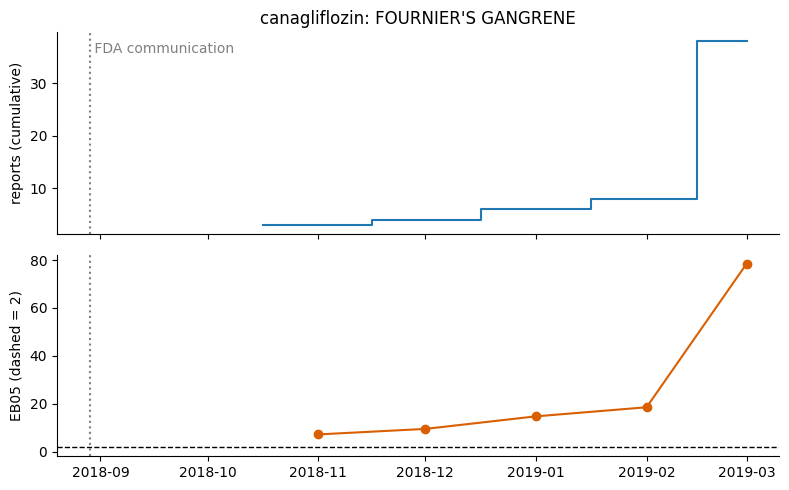

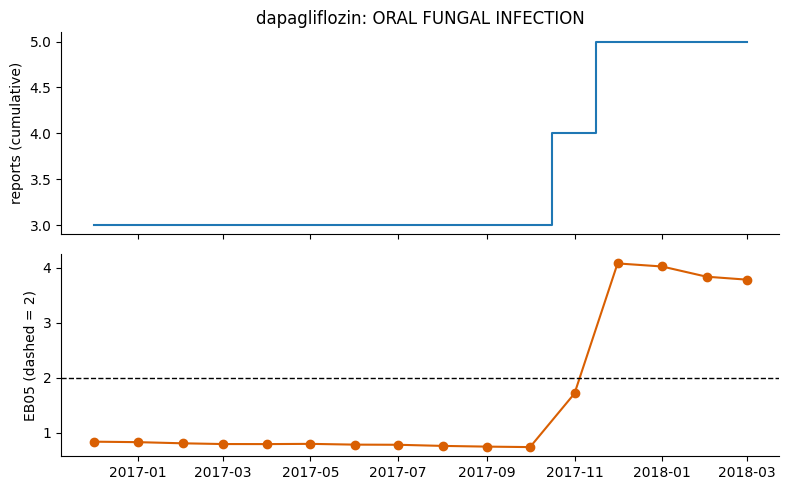

In [55]:
def plot_pair(pair, start, end, vline=None, vlabel=None):
    h = g.xs(pair, level="pair").reset_index()
    h = h[(h.m >= start) & (h.m <= end)]
    fig, ax = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
    ax[0].step(h.m, h.a, where="mid", color="#1f77b4"); ax[0].set_ylabel("reports (cumulative)")
    ax[1].plot(h.m, h.EB05, marker="o", color="#d95f02"); ax[1].axhline(2, color="k", ls="--", lw=1)
    ax[1].set_ylabel("EB05 (dashed = 2)")
    for a_ in ax:
        if vline: a_.axvline(pd.Timestamp(vline), color="grey", ls=":")
    if vline: ax[0].text(pd.Timestamp(vline), ax[0].get_ylim()[1] * 0.9, " " + vlabel, color="grey")
    ax[0].set_title(f"{pair[0]}: {pair[1]}")
    return fig

plot_pair(("canagliflozin", "FOURNIER'S GANGRENE"), "2018-01-01", "2019-03-01", "2018-08-29", "FDA communication")
save("07a_fourniers")
plot_pair(("dapagliflozin", "ORAL FUNGAL INFECTION"), "2016-12-01", "2018-03-01")
save("07b_oral_fungal")

## 9. Time-series forecast arms (C and D)

Arm B shows that history features help. Arm C asks whether an **explicit forecast** of the report counts adds anything beyond them. For each at-risk pair and cutoff *t*, using only data up to *t*:

1. forecast the cumulative report count *a* and the cumulative expected count *E* at *t* + 12 months from the last 12 monthly increments;
2. recompute EB05 from the forecast (`EB05_hat`, using the same prior) and use it as the ranking score.

Two simple forecasts are compared:

* **C1, flat:** the average of the last 12 monthly increments is projected forward.
* **C2, trend:** a least-squares line through the 12 increments is projected forward (floored at zero).

Arm D adds the forecast features (`lEB05_hat`, forecast growth, forecast change in EB05) to the level-and-age logistic model S1. More elaborate forecasts (ETS/ARIMA, pooled models with lag features) were not tried; sparse monthly counts make them unlikely to be stable.

### 9.1 Wide tables and the forecasting function

In [56]:
# one row per pair, one column per month (cumulative reports a, cumulative expected E)
e_long = con.sql("SELECT ingredient, pt, m, E FROM fc_pair_month_e").df()
e_long["m"] = pd.to_datetime(e_long.m)
e_long["pid"] = [pid_map.get(p_) for p_ in zip(e_long.ingredient, e_long.pt)]
E_w = e_long.pivot(index="pid", columns="m", values="E")
A_w = a_s.unstack("m")                          # a_s is indexed by (pid, m)

HF, W = 12, 12                                  # forecast horizon, history window (months)

def forecast_total(wide, pids, t, method):
    """Cumulative value at t + HF, using only data up to t."""
    cols = pd.date_range(t - pd.DateOffset(months=W), t, freq="MS")     # 13 cumulative points
    cum = wide.loc[pids, cols].values
    inc = np.clip(np.diff(cum, axis=1), 0, None)                         # 12 monthly increments
    if method == "flat":
        f = np.repeat(inc.mean(axis=1, keepdims=True), HF, axis=1)
    else:                                                                # "trend": least-squares line
        x = np.arange(W); xm = x.mean()
        slope = ((x - xm) * (inc - inc.mean(1, keepdims=True))).sum(1) / ((x - xm) ** 2).sum()
        icpt = inc.mean(1) - slope * xm
        f = np.clip(icpt[:, None] + slope[:, None] * np.arange(W, W + HF), 0, None)
    return cum[:, -1] + f.sum(axis=1)

### 9.2 Add the forecasts to the panel

In [57]:
def add_forecasts(panel, method):
    out = panel.copy()
    a_hat, E_hat = np.zeros(len(out)), np.zeros(len(out))
    for t, ix in out.groupby("cutoff").indices.items():       # ix = row positions for this cutoff
        pids = out.pid.values[ix]
        a_hat[ix] = forecast_total(A_w, pids, t, method)
        E_hat[ix] = forecast_total(E_w, pids, t, method)
    E_hat = np.maximum(E_hat, 1e-9)
    out["a_hat"], out["E_hat"] = a_hat, E_hat
    out["EB05_hat"] = [eb(a, E)[1] for a, E in zip(a_hat, E_hat)]
    out["lEB05_hat"] = np.log1p(out.EB05_hat)
    out["gr_hat"] = np.log(out.a_hat) - out.la               # forecast growth in reports
    out["deb_hat"] = out.EB05_hat - out.EB05                 # forecast change in EB05
    return out

panel_flat  = add_forecasts(panel, "flat")
panel_trend = add_forecasts(panel, "trend")

### 9.3 How accurate are the forecasts of the report count?

Mean absolute error on the log scale of the 12-month-ahead cumulative count, for "no change" (use *a* at *t*), flat and trend, pooled over all at-risk pairs and all 14 cutoffs.

In [58]:
rows = []
for name, pf in {"no change": None, "flat": panel_flat, "trend": panel_trend}.items():
    errs = []
    for t, x in panel.groupby("cutoff"):
        t12 = t + pd.DateOffset(months=12)
        true_a = A_w.loc[x.pid.values, t12].values
        if pf is None:
            pred = x.la.pipe(np.exp).values                    # a_t
        else:
            pred = pf.loc[x.index, "a_hat"].values
        errs.append(np.abs(np.log1p(pred) - np.log1p(true_a)))
    rows.append((name, np.concatenate(errs).mean()))
print(pd.DataFrame(rows, columns=["method", "mean abs error (log scale)"]).round(3))

      method  mean abs error (log scale)
0  no change                       0.284
1       flat                       0.197
2      trend                       0.327


| method | mean abs error (log scale) |
|---|---|
| no change (*a* at *t*) | 0.284 |
| flat (mean of last 12 monthly increments) | 0.197 |
| trend (least-squares line through 12 increments) | 0.327 |

* The flat forecast predicts the 12-month-ahead report count better than assuming no change (0.197 vs 0.284, about 31% lower).
* The straight-line trend is **worse than no change** (0.327 vs 0.284). A likely reason is that most pairs add few reports per month, so a line through 12 small, noisy increments is unstable and extrapolates badly. This was not tested directly, but it is a common outcome with sparse counts.
* The flat forecast is the main time-series method; the trend version is kept as a documented "tried, worse" comparison.

**Limits of this check:** it measures the accuracy of the report count only, not whether the forecast helps predict emergence (next section). Errors are pooled with no confidence interval, and the forecast of the expected count *E*, which also feeds EB05, is not evaluated separately.

### 9.4 Does the forecast predict emergence?

Pooled AP and recall@5% over the 7 test cutoffs for A (EB05 today), C1 (flat forecast EB05) and C2 (trend forecast EB05).

In [59]:
cut_test = pd.Timestamp("2017-03-01")
tf, tt = (p[p.cutoff >= cut_test] for p in (panel_flat, panel_trend))
tb = panel[panel.cutoff >= cut_test]

print("A  EB05 now      ", np.round(pooled(tb, "EB05"), 3))
print("C1 forecast flat ", np.round(pooled(tf, "EB05_hat"), 3))
print("C2 forecast trend", np.round(pooled(tt, "EB05_hat"), 3))

A  EB05 now       [0.368 0.553]
C1 forecast flat  [0.392 0.68 ]
C2 forecast trend [0.306 0.585]


Lead time of the flat-forecast ranking (C1) at the same alert budget:

In [60]:
tf = panel_flat[panel_flat.cutoff >= pd.Timestamp("2017-03-01")]
print(lead_times(tf, "EB05_hat"))

pairs that became signals    127.0
flagged early                108.0
% flagged early               85.0
median months early            6.0
average months early           6.3
dtype: float64


C1 flags 86.6% of the later signals early (median 6 months), similar to B1 (85.8%, 7 months) and above EB05 alone (68.5%, 5 months). No confidence interval was computed for this lead-time comparison.

### 9.5 Paired bootstrap: C and D versus the baselines

Paired bootstrap by pair (500 resamples, same seed throughout) of C1 − A, C1 − S1 and D − S1.

In [61]:
def walk_df(df, feats):
    parts = []
    for t in test_cuts:
        tr = df[df.cutoff <= t - pd.DateOffset(months=GAP)]
        te = df[df.cutoff == t].copy()
        m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                          LogisticRegression(C=0.5, max_iter=2000)).fit(tr[feats], tr.y)
        te["p"] = m.predict_proba(te[feats])[:, 1]
        parts.append(te)
    return pd.concat(parts)

S1 = ["lEB05", "lEBGM", "la", "months_since3", "sglt2"]
FC = ["lEB05_hat", "gr_hat", "deb_hat"]
wS1f = walk_df(panel_flat, S1)                   # level + age
wDf  = walk_df(panel_flat, S1 + FC)              # + flat-forecast features

cmp_ = wDf[["pid", "cutoff", "y", "EB05", "EB05_hat"]].copy()
cmp_["S1"], cmp_["D"] = wS1f.p.values, wDf.p.values      # same rows, same order
print("S1", np.round(pooled(cmp_, "S1"), 3), "| D", np.round(pooled(cmp_, "D"), 3))

rng = np.random.default_rng(0); pids_ = cmp_.pid.unique()
cols = ["EB05", "EB05_hat", "S1", "D"]
bb = {k: [] for k in cols}
for _ in range(500):
    x = cmp_.merge(pd.DataFrame({"pid": rng.choice(pids_, len(pids_), replace=True)}), on="pid")
    for k in cols: bb[k].append(pooled(x, k))
bb = {k: np.array(v) for k, v in bb.items()}

for name, a, b in [("C1 - A   (forecast EB05 vs EB05 now)", "EB05_hat", "EB05"),
                   ("C1 - S1  (forecast vs level + age model)", "EB05_hat", "S1"),
                   ("D  - S1  (forecast features added)", "D", "S1")]:
    d = bb[a] - bb[b]
    print(name, "| AP", np.percentile(d[:, 0], [2.5, 97.5]).round(3),
          "| recall@5%", np.percentile(d[:, 1], [2.5, 97.5]).round(3))

S1 [0.434 0.726] | D [0.447 0.747]
C1 - A   (forecast EB05 vs EB05 now) | AP [-0.048  0.117] | recall@5% [0.069 0.176]
C1 - S1  (forecast vs level + age model) | AP [-0.085  0.026] | recall@5% [-0.127  0.015]
D  - S1  (forecast features added) | AP [-0.019  0.04 ] | recall@5% [-0.021  0.048]


**Arms C and D: does the forecast add anything? (7 test cutoffs)**

| comparison | AP difference (95% interval) | recall@5% difference (95% interval) |
|---|---|---|
| C1 − A: flat forecast vs EB05 today | −0.061 to 0.115 | **0.092 to 0.210** |
| C1 − S1: flat forecast vs level-and-age model | −0.091 to 0.013 | −0.095 to 0.030 |
| D − S1: forecast features added to S1 | −0.015 to 0.039 | −0.022 to 0.053 |

Point estimates: S1 AP 0.434, recall@5% 0.726; D AP 0.449, recall@5% 0.744.

* **The flat forecast beats EB05 today on recall.** The recall@5% interval is above zero, so ranking by forecast EB05 captures more future signals than ranking by today's EB05 at the same alert budget. There is no reliable AP gain.
* **It does not beat the simple level-and-age model.** Both C1 − S1 intervals include zero, and the point estimates slightly favour S1.
* **Adding forecast features to the level-and-age model does not help.** Both D − S1 intervals include zero and the point gain is under 0.02.
* **Conclusion:** most of the benefit comes from combining EB05 level with report count, pair age and drug class. An explicit forecast of reports and expected counts adds no reliable improvement beyond that.

**Limitations:** 7 overlapping cutoffs and about 127 positive pairs give wide intervals, the bootstrap ignores correlation between cutoffs, and the intervals do not demonstrate equivalence: "no reliable difference" is not "no difference".

Same comparison for the trend forecast (C2 − A), and for flat versus trend (C1 − C2). The D − S1 line repeats the result above (same seed).

In [62]:
d_ = wS1f[["pid", "cutoff", "y"]].copy()
d_["A"] = wS1f.EB05                                              # EB05 now
d_["C2"], d_["S1"], d_["D"] = tt.EB05_hat.values, wS1f.p.values, wDf.p.values

rng = np.random.default_rng(0); pids_ = d_.pid.unique()
bb = {k: [] for k in ["A", "C2", "S1", "D"]}
for _ in range(500):
    x = d_.merge(pd.DataFrame({"pid": rng.choice(pids_, len(pids_), replace=True)}), on="pid")
    for k in bb: bb[k].append(pooled(x, k))
bb = {k: np.array(v) for k, v in bb.items()}

for name, a, b in [("C2 - A (forecast vs EB05 now)", "C2", "A"),
                   ("D - S1 (forecast features added)", "D", "S1")]:
    d = bb[a] - bb[b]
    print(name, "| AP", np.percentile(d[:, 0], [2.5, 97.5]).round(3),
          "| recall@5%", np.percentile(d[:, 1], [2.5, 97.5]).round(3))

C2 - A (forecast vs EB05 now) | AP [-0.137  0.036] | recall@5% [-0.058  0.122]
D - S1 (forecast features added) | AP [-0.019  0.04 ] | recall@5% [-0.021  0.048]


In [63]:
assert len(tt) == len(cmp_)                      # same rows, same order
cmp_["EB05_hat_trend"] = tt.EB05_hat.values

rng = np.random.default_rng(0); pids_ = cmp_.pid.unique()
bc = {k: [] for k in ["EB05_hat", "EB05_hat_trend"]}
for _ in range(500):
    x = cmp_.merge(pd.DataFrame({"pid": rng.choice(pids_, len(pids_), replace=True)}), on="pid")
    for k in bc: bc[k].append(pooled(x, k))
d = np.array(bc["EB05_hat"]) - np.array(bc["EB05_hat_trend"])
print("C1 (flat) - C2 (trend) | AP", np.percentile(d[:, 0], [2.5, 97.5]).round(3),
      "| recall@5%", np.percentile(d[:, 1], [2.5, 97.5]).round(3))

C1 (flat) - C2 (trend) | AP [0.023 0.158] | recall@5% [0.016 0.16 ]


* **The trend forecast (C2) is not reliably better than EB05 today** (C2 − A: AP [−0.135, 0.042], recall@5% [−0.058, 0.124]).
* **The flat forecast is reliably better than the trend forecast** (C1 − C2: AP [0.018, 0.141], recall@5% [0.035, 0.188]). This agrees with the count-accuracy result in Section 9.3: with sparse counts, extrapolating a straight line is worse than extrapolating a plain average.

## 10. Summary figures

Figures for the arms A, B1 and B2, the ablation and the model weights, saved to `outputs/signal_identification_v1/figures/`. Results for the forecast arms (C, D) are reported in the tables of Section 9 only.

In [64]:
COL = {"A: EB05": "#7f7f7f", "B1: logistic": "#1f77b4", "B2: boosting": "#d95f02"}

### Figure 1: Per-cutoff performance, EB05 versus the ML models

In [ ]:
def per_cut(d, s, pct=0.05):
    rows = []
    for t, x in d.groupby("cutoff"):
        k = max(1, int(round(pct * len(x))))
        rows.append((t, average_precision_score(x.y, x[s]),
                     x.sort_values(s, ascending=False).y.head(k).sum() / x.y.sum(), x.y.mean()))
    return pd.DataFrame(rows, columns=["cutoff", "ap", "rec5", "prev"]).set_index("cutoff")

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for name, s in {"A: EB05": "EB05", "B1: logistic": "p_lr", "B2: boosting": "p_gb"}.items():
    pc = per_cut(test, s)
    ax[0].plot(pc.index, pc.ap, marker="o", color=COL[name], label=name)
    ax[1].plot(pc.index, pc.rec5, marker="o", color=COL[name], label=name)
ax[0].plot(pc.index, pc.prev, ls=":", color="k", label="prevalence (chance)")
ax[0].set_title("Average precision by cutoff"); ax[1].set_title("Recall in top 5% by cutoff")
ax[0].legend(frameon=False)
for a in ax: a.tick_params(axis="x", rotation=30); a.set_ylim(0, None)
save("01_per_cutoff")

### Figure 2: Pooled results with 95% intervals

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for j, metric in enumerate(["Average precision", "Recall in top 5%"]):
    for i, k in enumerate(scores):
        lo, hi = np.percentile(boot[k][:, j], [2.5, 97.5])
        ax[j].errorbar(i, base[k][j], yerr=[[base[k][j] - lo], [hi - base[k][j]]],
                       fmt="o", ms=8, capsize=5, color=COL[k])
    ax[j].set_xticks(range(3)); ax[j].set_xticklabels(list(scores), rotation=15)
    ax[j].set_title(metric); ax[j].set_ylim(0, None)
save("02_pooled")

### Figure 3: Gain over EB05, with and without the 2018-09 cutoff

In [ ]:
items = []
for lab_, bt, key in [("all 7 cutoffs", boot, {"B1": "B1: logistic", "B2": "B2: boosting", "A": "A: EB05"}),
                      ("without 2018-09", boot2, {"B1": "p_lr", "B2": "p_gb", "A": "EB05"})]:
    for m in ["B1", "B2"]:
        d = bt[key[m]] - bt[key["A"]]
        items.append((f"{m}, {lab_}", d.mean(0), np.percentile(d, [2.5, 97.5], axis=0)))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for j, metric in enumerate(["AP difference vs EB05", "Recall@5% difference vs EB05"]):
    for i, (lbl, mean, ci) in enumerate(items):
        ax[j].errorbar(mean[j], i, xerr=[[mean[j] - ci[0, j]], [ci[1, j] - mean[j]]], fmt="o", capsize=4, color="#1f77b4")
    ax[j].axvline(0, color="k", lw=1); ax[j].set_title(metric)
    ax[j].set_yticks(range(len(items))); ax[j].set_yticklabels([x[0] for x in items])
save("03_gain_over_eb05")

### Figure 4: Early detection (share flagged and lead-time distribution)

In [ ]:
S = ["EB05", "p_lr", "p_gb"]; nm = {"EB05": "A: EB05", "p_lr": "B1: logistic", "p_gb": "B2: boosting"}
bpos = pp[pp.pos]
boot_lead = res                                  # our bootstrap table from the lead-time cell

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for i, s in enumerate(S):
    est = 100 * bpos["flag_" + s].mean()
    lo, hi = np.percentile(boot_lead["pct_" + s], [2.5, 97.5])
    ax[0].errorbar(i, est, yerr=[[est - lo], [hi - est]], fmt="o", ms=8, capsize=5, color=COL[nm[s]])
ax[0].set_xticks(range(3)); ax[0].set_xticklabels([nm[s] for s in S], rotation=15)
ax[0].set_ylabel("% of later signals flagged early"); ax[0].set_ylim(0, 100)

w = 0.27
for i, s in enumerate(S):
    cnt = bpos["lead_" + s].dropna().value_counts().reindex(range(1, 13), fill_value=0)
    bw=0.27
    ax[1].bar(np.arange(1, 13) + (i - 1) * bw, cnt.values, bw, color=COL[nm[s]], label=nm[s])
ax[1].set_xlabel("months between first alert and signal (capped at 12 by design)")
ax[1].set_ylabel("number of pairs"); ax[1].legend(frameon=False)
save("04_lead_time")

### Figure 5: Ablation, level and age versus growth

In [ ]:
sets_ab = {"S0: EB05 only": "s0", "S1: + count, age, class": "s1", "S2: + growth": "s2"}
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for j, metric in enumerate(["Average precision", "Recall in top 5%"]):
    for i, (lbl, k) in enumerate(sets_ab.items()):
        est = pooled(ab, k)[j]
        lo, hi = np.percentile(bs[k][:, j], [2.5, 97.5])
        ax[j].errorbar(i, est, yerr=[[est - lo], [hi - est]], fmt="o", ms=8, capsize=5, color="#1f77b4")
    ax[j].set_xticks(range(3)); ax[j].set_xticklabels(list(sets_ab), rotation=15, ha="right")
    ax[j].set_title(metric); ax[j].set_ylim(0, None)
save("05_ablation")

### Figure 6: Which features the logistic model uses

In [ ]:
tr = panel[panel.cutoff <= pd.Timestamp("2018-09-01") - pd.DateOffset(months=GAP)]
m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                  LogisticRegression(C=0.5, max_iter=2000)).fit(tr[FEATS], tr.y)
coef = pd.Series(m[-1].coef_[0], index=FEATS).sort_values()

fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(coef.index, coef.values, color=np.where(coef.values >= 0, "#1f77b4", "#d95f02"))
ax.axvline(0, color="k", lw=1); ax.set_xlabel("weight on standardised feature")
ax.set_title("Logistic model: last training window")
save("06_coefficients")

## 11. Summary, limitations and next steps

### Summary

| Question | Answer (7 test cutoffs, 12-month horizon, top-5% watch list) |
|---|---|
| Does today's EB05 already predict emergence? | Yes: recall 0.55 and a lift of 10–21× over chance at most cutoffs. Report count alone does not (lift about 1). |
| Do history-based models do better? | They catch more future signals: recall 0.73 (B1) and 0.70 (B2) vs 0.55; the gain survives dropping the last cutoff. The AP gain is not established. |
| What drives the gain? | EB05 level, report count, pair age and drug class, **not** recent growth. |
| Does an explicit forecast of report counts help? | A flat forecast ranks as well as the best models on recall (0.70) and beats EB05 today, but adds nothing beyond the level-and-age model. A linear-trend forecast is worse. |
| Do the methods find signals *earlier*? | Not demonstrably: they flag more of the later signals (about 85% vs 69%) but median lead-time differences are within noise. |
| What cannot be predicted? | Abrupt, event-driven signals such as Fournier's gangrene after the Aug 2018 FDA communication. |

These methods are decision support for experts. A high rank means "look at this pair first", not that the medicine caused the event, and expert review of every alert stays essential.

### Limitations

1. **Prior leakage.** The EBGM prior was fitted on data up to 2019 and is used for all earlier months. A sensitivity analysis with the prior refitted at each year-end has not been run.
2. **Label leakage.** Excluding `censored` and `control_burn_in` pairs uses full-sample labels (13 and 203 pairs for the primary label).
3. **Small, overlapping test window.** 7 test cutoffs (6 without 2018-09) with overlapping 12-month windows and 127 positive pairs. The bootstrap resamples pairs and ignores correlation between cutoffs, so intervals are optimistic.
4. **Correlated events.** Related event terms (for example the Fournier's gangrene family and the 2019Q3 cluster) inflate the effective sample. Results grouped by event family have not been produced.
5. **Pooled evaluation.** One model for all drugs; results by drug class are not reported, and semaglutide and ertugliflozin enter the at-risk set late.
6. **Conditional on *a* ≥ 3.** Pairs with fewer than three reports are never ranked.
7. **Lead time** is capped at 12 months, is measured against the strong-signal rule, and medians are computed only among flagged pairs.
8. **Sensitivity labels not evaluated.** Labels for *K* = 6, burn-in 2014-12 and 2015-12 are saved but the models have not been rerun on them. The 2018-09 exclusion (Section 7.2) was done for arms A and B only.
9. **Simple forecasts only** (flat and linear trend); the boosting model was not tuned.

### Next steps

1. Re-check every reported number and compute lead time with a bootstrap interval for the forecast arms (C, D).
2. Run the open sensitivity analyses: prior refit by year, alternative labels (*K* = 6, other burn-ins), event-family grouping, results by drug class.
3. Add a check on known labelling: for each watch-list pair, was the event already on the FDA drug label, and since when (the next notebook, using official FDA drug labels from 2014).

## Headline results

Seven test cutoffs (Mar 2017 – Sep 2018), 12-month horizon, watch list = top 5% of at-risk pairs. Detailed results, intervals and caveats are in the sections named in the last column.

| Arm | Ranking method | Avg. precision | Recall in top 5% | Later signals flagged early* | Median lead time* | Section |
|---|---|---|---|---|---|---|
| A | EB05 today (baseline) | 0.37 | 0.55 | 68.5% | 5 months | 5, 8 |
| B1 | Logistic regression on report-history features | 0.44 | 0.73 | 85.8% | 7 months | 6, 8 |
| B2 | Gradient boosting, same features | 0.43 | 0.70 | 84.3% | 6 months | 6, 8 |
| C1 | EB05 computed from a *flat* 12-month forecast of counts | 0.38 | 0.70 | 86.6% | 6 months | 9 |
| C2 | EB05 computed from a *linear-trend* forecast of counts | 0.31 | 0.59 | not computed | not computed | 9 |
| D | B1 features plus forecast features | 0.45 | 0.74 | not computed | not computed | 9 |

\*Share of the later signals that were on the watch list at least once in the 12 months before onset, and median months between first alert and onset among those flagged (Section 8).

**What can and cannot be concluded**

* Models that use report history (B1, B2) and the flat forecast (C1) put **more of the future strong signals on the watch list** than EB05 alone. The recall gain is statistically reliable (95% bootstrap intervals above zero); the average-precision gain is not.
* The gain comes from **how large and how old** a pair is (EB05 level, report count, pair age, drug class), **not from recent growth**. Adding growth features or explicit forecast features gives no reliable further improvement.
* The methods find **more** future signals but we **cannot show that they find them earlier**: lead-time differences are within noise.
* **Abrupt, event-driven signals are not predictable** from report history. Fournier's gangrene appeared right after an FDA safety communication (Aug 2018) and was never in the at-risk set.
* All results are interim: the test window is short (7 overlapping cutoffs, 127 positive pairs) and several sensitivity analyses are still open (Section 11).

## Close the database connection

In [ ]:
con.close()

# Explicitly close any ambient DuckDB connections
try:
    duckdb.close()
    print("✓ Closed ambient DuckDB connection.")
except Exception as e:
    print(f"Notice: {e}")